# 1.04. Методы ускорения A/B-тестов

**План занятия**

1. Зачем ускорять A/B-тесты и что можно изменить в дизайне теста.
2. Методы уменьшения дисперсии: очистка от выбросов, стратификация, линеаризация, VWE, CUPED и его ML-расширения. Там же бакетизация: она ускоряет вычисления, а не сам тест.
3. Как выбрать метод.
4. Культура тестирования: почему процессы ускоряют эксперименты не меньше математики.


### Библиотеки и общие функции


In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from ipywidgets import FloatSlider, IntSlider, interact
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from statsmodels.stats.proportion import proportion_confint
from tqdm import tqdm

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
ALPHA = 0.05


def masked_mean_var(x: np.ndarray, mask: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Считает среднее, дисперсию и размер выборки по строкам x, учитывая только наблюдения из mask."""
    n = mask.sum(axis=1)
    mean = (x * mask).sum(axis=1) / n
    var = ((x ** 2 * mask).sum(axis=1) - n * mean ** 2) / (n - 1)
    return mean, var, n


def z_pvalue(delta: np.ndarray, se: np.ndarray) -> np.ndarray:
    """Возвращает двустороннее p-value для разницы delta со стандартной ошибкой se."""
    return 2 * stats.norm.sf(np.abs(delta / se))


def rate_with_ci(rejected: np.ndarray) -> tuple[float, float, float]:
    """Возвращает долю отклонений H0 и её 95% ДИ Уилсона."""
    low, high = proportion_confint(rejected.sum(), rejected.size, method='wilson')
    return float(rejected.mean()), float(low), float(high)


def plot_rates(ax: plt.Axes, rates: dict[str, np.ndarray], title: str, reference: float | None = ALPHA) -> None:
    """Рисует доли отклонений H0 с 95% ДИ: одна точка на метод."""
    names = list(rates)[::-1]
    values = np.array([rate_with_ci(rates[name]) for name in names])
    ax.errorbar(values[:, 0], names, xerr=[values[:, 0] - values[:, 1], values[:, 2] - values[:, 0]],
                fmt='o', color=BLUE, capsize=4)
    if reference is not None:
        ax.axvline(reference, color=RED, linestyle='--', label=f'Заявленный уровень {reference:.0%}')
        ax.legend(loc='lower right')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax.set_title(title)


## Зачем ускорять A/B-тесты


Основная предпосылка для ускорения A/B-тестов — стремление **повысить их чувствительность**. Более чувствительный тест при тех же вероятностях ошибок обнаруживает меньшие эффекты или требует меньше данных.

Причины ускорять A/B-тесты:

* **Скорость проверки гипотез.** Чем быстрее завершается тест, тем больше гипотез можно проверить за то же время и тем быстрее развивается продукт.
* **Меньше ожидания.** Менеджеры хотят получать результаты как можно раньше, а длительные тесты (иногда на месяцы) задерживают решения. Ускорение сокращает очередь и освобождает слоты для новых экспериментов.
* **Экономия данных.** Чувствительному тесту нужно меньше наблюдений, а значит, меньше трафика.
* **Обнаружение малых эффектов.** Небольшие улучшения со временем складываются в большие. Повышенная чувствительность позволяет их заметить.
* **Меньше потерь.** Если изменение вредит продукту, тест на меньшей выборке затронет меньше пользователей.


## Что можно изменить в дизайне теста

У каждого A/B-теста есть обязательные составляющие. Самый простой, хотя и не всегда возможный способ ускорить тестирование — изменить их:

| № | Составляющая | Что можно сделать |
|---|---|---|
| 1 | Формулировка гипотезы | Уточнить гипотезу, чтобы проверять меньше метрик. Чем меньше проверок, тем мягче поправка на множественность ([лекция 1.03](<../03. Множественное тестирование гипотез/lecture.ipynb>)) и тем меньше нужна выборка. |
| 2 | Количество тестовых групп | Проверить несколько вариантов фичи в одном тесте вместо N отдельных. Трафик при этом делится на большее число групп, а сравнения требуют поправки на множественность, поэтому выигрыш есть не всегда. |
| 3 | Метрики для принятия решений | Выбрать более чувствительные метрики. Косвенная метрика подходит, только если она связана с целевой. |
| 4 | Ошибки I и II рода | Согласиться на более высокие вероятности ошибок. Это сократит выборку, но увеличит риск неверного решения. |
| 5 | Статистический критерий | Подобрать наиболее мощный критерий, контролирующий ошибку I рода на заданном уровне. |
| 6 | Минимально детектируемый эффект (MDE) | Принять, что нас интересуют только эффекты побольше. Рост MDE сокращает выборку квадратично. |
| 7 | Дизайн эксперимента | Использовать последовательное тестирование вместо теста с фиксированным горизонтом, чтобы останавливать тест раньше ([лекция 2.01](<../../../2. Квази-эксперименты/Теоретический блок/01. Последовательное тестирование>)). |


Если всё это уже согласовано, придётся действовать хитрее. Длительность теста напрямую зависит от размера выборки. Вспомним, как он считается для одной группы при равных дисперсиях:

$$
N = \frac{\left( \Phi^{-1}_{(1 - \alpha/2)} + \Phi^{-1}_{(1-\beta)} \right)^2 \times 2 \sigma^2}{MDE^2}
$$

Осталась дисперсия $\sigma^2$, и $N$ линейно зависит от неё: снизив дисперсию вдвое, мы вдвое сократим тест.

**Попробуйте сами.** Эта ячейка интерактивная: запустите её в Colab или Jupyter и подвигайте ползунки.


In [2]:
def duration_demo(mde: float = 20.0, sigma: float = 300.0, variance_cut: float = 0.5, daily_users: int = 500) -> None:
    """Показывает, как снижение дисперсии сокращает необходимую выборку и длительность теста."""
    z_sum = stats.norm.ppf(0.975) + stats.norm.ppf(0.8)
    sizes = [2 * z_sum ** 2 * sigma ** 2 * share / mde ** 2 for share in (1.0, 1 - variance_cut)]
    days = [2 * size / daily_users for size in sizes]

    fig, ax = plt.subplots(figsize=(9, 2.6))
    bars = ax.barh(['С уменьшенной дисперсией', 'Исходная дисперсия'], days[::-1], color=[GREEN, GRAY])
    ax.bar_label(bars, labels=[f'{d:.0f} дн. ({s:,.0f} на группу)' for d, s in zip(days[::-1], sizes[::-1])], padding=4)
    ax.set_xlim(0, days[0] * 1.45)
    ax.set_xlabel('Длительность теста, дни')
    ax.set_title(f'Дисперсия ниже на {variance_cut:.0%}: тест короче на {variance_cut:.0%}')
    plt.tight_layout()
    plt.show()


interact(duration_demo,
         mde=FloatSlider(value=20, min=5, max=100, step=5, description='MDE'),
         sigma=FloatSlider(value=300, min=50, max=1000, step=50, description='σ'),
         variance_cut=FloatSlider(value=0.5, min=0, max=0.9, step=0.05, description='Снижение σ²'),
         daily_users=IntSlider(value=500, min=100, max=5000, step=100, description='Трафик/день'));


## Методы уменьшения дисперсии

| Метод | Что делает | Что для него нужно |
|---|---|---|
| Очистка от выбросов | Ограничивает влияние экстремальных значений | Порог или список пользователей, не зависящие от воздействия |
| Стратификация | Убирает дисперсию между сегментами | Сегменты, известные до теста |
| Бакетизация | **Не снижает дисперсию эффекта**, ускоряет вычисления | Случайное разбиение пользователей на бакеты |
| Линеаризация | **Не снижает дисперсию сама**, делает метрику отношения пользовательской | Числитель и знаменатель по пользователям |
| VWE | Даёт больший вес менее шумным пользователям | История поведения пользователя |
| CUPED | Вычитает объяснимую ковариатой часть метрики | Ковариата, не зависящая от воздействия |
| Predictive CUPED, CUPAC, MLRATE | Строят ковариату с помощью модели | Признаки до теста и правильная схема обучения |


### [Очистка данных от выбросов](https://habr.com/ru/companies/avito/articles/571094/#:~:text=%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D1%8B%20%D0%B1%D0%BE%D1%80%D1%8C%D0%B1%D1%8B%20%D1%81%20%D0%B2%D1%8B%D0%B1%D1%80%D0%BE%D1%81%D0%B0%D0%BC%D0%B8%20%D0%B2%20%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D1%85)


Чем больше выбросов, тем выше дисперсия и тем менее мощный у нас критерий. Поэтому аналитикам часто приходит в голову **убрать n% пользователей с самой большой (или самой маленькой) метрикой в тесте и контроле**.

Идея здравая, но подходить к ней нужно осторожно:

1. Неправильная реализация может исказить результаты эксперимента.
2. Убирая топ пользователей и принимая решение по остальным, мы неявно считаем, что топ-пользователи отреагируют на изменение так же, как остальные, или лучше. Это не всегда так, и это стоит проверять отдельно.

Сравним способы очистки на одних и тех же данных. Выручка пользователя скошена вправо, средняя выручка равна 1000. В A/B-тесте она вырастает у всех на 15%, так что истинный эффект равен 150. Отрезаем верхний 1%.


Истинный эффект на всю аудиторию: 150
                                   Ошибка I рода  Мощность  Оценка эффекта  SD оценки  Средняя SE
Без очистки                                0.048     0.603         149.818     68.609      68.049
Свой порог в каждой группе                 0.083     0.699         137.360     61.150      54.037
Свой порог + поправка SE                   0.050     0.621         137.360     61.150      60.943
Общий порог по тесту и контролю            0.054     0.536         110.578     54.179      53.817
Порог по контролю                          0.054     0.466          98.138     51.777      51.878
Порог предпериода к метрике теста          0.056     0.518         104.315     51.841      51.800
Исключение по выручке до теста             0.048     0.603         147.653     67.386      66.918
Винзоризация порогом предпериода           0.051     0.623         132.991     59.072      58.753


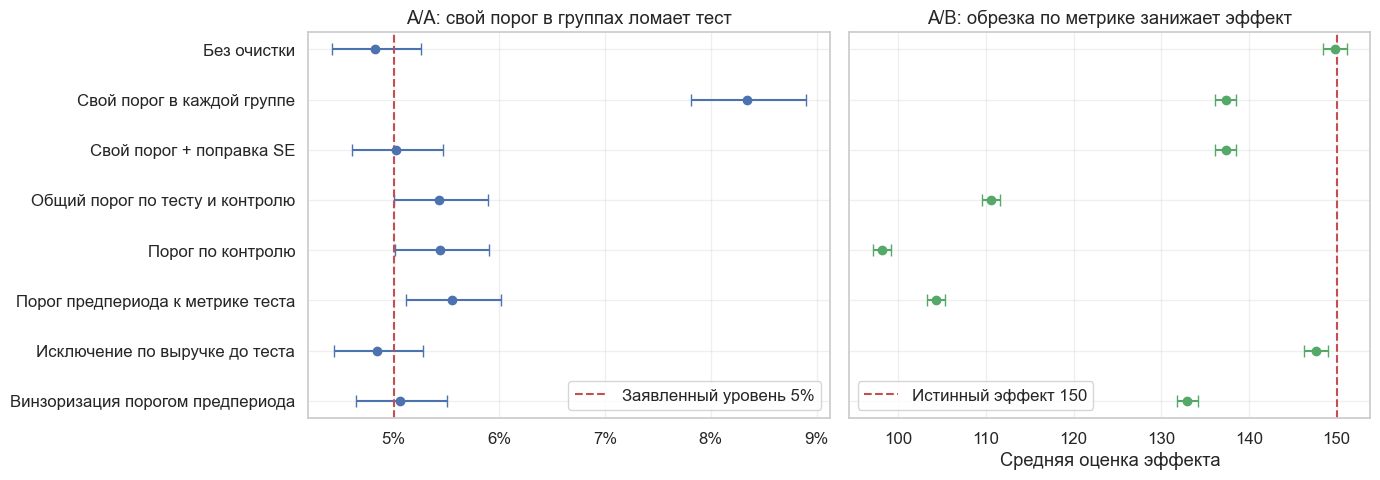

In [3]:
OUTLIER_CONFIG = {
    "n_simulations": 10_000,
    "sample_size": 1_000,
    "tail_share": 0.01,
    "lift": 1.15,  # эффект: выручка каждого пользователя выросла на 15%
}
OUTLIER_TRUE_EFFECT = 1_000 * (OUTLIER_CONFIG["lift"] - 1)


def generate_revenue(rng: np.random.Generator, size: tuple[int, int], lift: float = 1.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует выручку пользователя до и во время эксперимента. Средняя выручка до эксперимента равна 1000."""
    activity = rng.gamma(2, 500, size)  # постоянная часть: активные пользователи тратят больше в оба периода
    return activity * rng.exponential(1, size), lift * activity * rng.exponential(1, size)


def clean_and_compare(pre_c: np.ndarray, y_c: np.ndarray, pre_t: np.ndarray, y_t: np.ndarray,
                      tail_share: float) -> dict[str, tuple[np.ndarray, np.ndarray]]:
    """Применяет способы очистки и для каждого возвращает оценку эффекта и её стандартную ошибку."""
    level = 1 - tail_share
    n = y_c.shape[1]
    q_c = np.quantile(y_c, level, axis=1, keepdims=True)
    q_t = np.quantile(y_t, level, axis=1, keepdims=True)
    q_pooled = np.quantile(np.hstack([y_c, y_t]), level, axis=1, keepdims=True)
    q_pre = np.quantile(np.hstack([pre_c, pre_t]), level, axis=1, keepdims=True)

    def compare(x_c, mask_c, x_t, mask_t):
        mean_c, var_c, n_c = masked_mean_var(x_c, mask_c)
        mean_t, var_t, n_t = masked_mean_var(x_t, mask_t)
        return mean_t - mean_c, np.sqrt(var_c / n_c + var_t / n_t)

    everyone = np.ones_like(y_c, dtype=bool)
    per_group = compare(y_c, y_c <= q_c, y_t, y_t <= q_t)
    # SE усечённого среднего, учитывающая случайность порога: дисперсия винзоризованной метрики / (1 - доля)^2
    yuen_var = (np.minimum(y_c, q_c).var(axis=1, ddof=1) + np.minimum(y_t, q_t).var(axis=1, ddof=1)) / level ** 2
    return {
        'Без очистки': compare(y_c, everyone, y_t, everyone),
        'Свой порог в каждой группе': per_group,
        'Свой порог + поправка SE': (per_group[0], np.sqrt(yuen_var / n)),
        'Общий порог по тесту и контролю': compare(y_c, y_c <= q_pooled, y_t, y_t <= q_pooled),
        'Порог по контролю': compare(y_c, y_c <= q_c, y_t, y_t <= q_c),
        'Порог предпериода к метрике теста': compare(y_c, y_c <= q_pre, y_t, y_t <= q_pre),
        'Исключение по выручке до теста': compare(y_c, pre_c <= q_pre, y_t, pre_t <= q_pre),
        'Винзоризация порогом предпериода': compare(np.minimum(y_c, q_pre), everyone, np.minimum(y_t, q_pre), everyone),
    }


def simulate_outliers(n_simulations: int, sample_size: int, tail_share: float, lift: float,
                      batch: int = 500) -> dict[str, dict[str, np.ndarray]]:
    """Прогоняет A/A и A/B и собирает оценки эффекта, SE и решения по каждому способу очистки."""
    rng = np.random.default_rng(42)
    result: dict[str, dict[str, list]] = {}
    for _ in range(n_simulations // batch):
        for key, group_lift in (('aa', 1.0), ('ab', lift)):
            pre_c, y_c = generate_revenue(rng, (batch, sample_size))
            pre_t, y_t = generate_revenue(rng, (batch, sample_size), group_lift)
            for name, (delta, se) in clean_and_compare(pre_c, y_c, pre_t, y_t, tail_share).items():
                row = result.setdefault(name, {'aa': [], 'ab': [], 'delta': [], 'se': []})
                row[key].append(z_pvalue(delta, se) < ALPHA)
                if key == 'ab':
                    row['delta'].append(delta)
                    row['se'].append(se)
    return {name: {key: np.concatenate(values) for key, values in row.items()} for name, row in result.items()}


outlier_results = simulate_outliers(**OUTLIER_CONFIG)
outlier_table = pd.DataFrame({
    name: {
        'Ошибка I рода': row['aa'].mean(),
        'Мощность': row['ab'].mean(),
        'Оценка эффекта': row['delta'].mean(),
        'SD оценки': row['delta'].std(),
        'Средняя SE': row['se'].mean(),
    } for name, row in outlier_results.items()
}).T
print(f'Истинный эффект на всю аудиторию: {OUTLIER_TRUE_EFFECT:.0f}')
print(outlier_table.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_rates(axes[0], {name: row['aa'] for name, row in outlier_results.items()}, 'A/A: свой порог в группах ломает тест')
names = list(outlier_results)[::-1]
axes[1].errorbar(outlier_table.loc[names, 'Оценка эффекта'], names,
                 xerr=1.96 * outlier_table.loc[names, 'SD оценки'] / np.sqrt(OUTLIER_CONFIG['n_simulations']),
                 fmt='o', color=GREEN, capsize=4)
axes[1].axvline(OUTLIER_TRUE_EFFECT, color=RED, linestyle='--', label=f'Истинный эффект {OUTLIER_TRUE_EFFECT:.0f}')
axes[1].set_title('A/B: обрезка по метрике занижает эффект')
axes[1].set_xlabel('Средняя оценка эффекта')
axes[1].legend(loc='lower left')
plt.tight_layout()
plt.show()


#### Нельзя чистить данные своим порогом в каждой группе

Самый очевидный способ — посчитать 99-й перцентиль в тесте, в контроле и отрезать всё, что выше, — даёт ошибку I рода 8.3% вместо 5%, то есть метод некорректен.

Дело в том, что порог оценён по тем же данным, которые мы затем сравниваем. Из-за шума он в каждой группе свой, и этот шум попадает в оценку эффекта, а t-тест о нём не знает: он считает порог заранее заданным. Поэтому средняя стандартная ошибка (54.0) занижена по сравнению с реальным разбросом оценки (61.1). Если учесть случайность порога (дисперсия винзоризованной метрики, делённая на $(1 - \text{доля})^2$, как в тесте Юэна), ошибка возвращается к 5.0%. Но оценивать мы будем уже разницу усечённых средних, а не эффект на всю аудиторию.

Чем больше отрезаем, тем сильнее проблема:


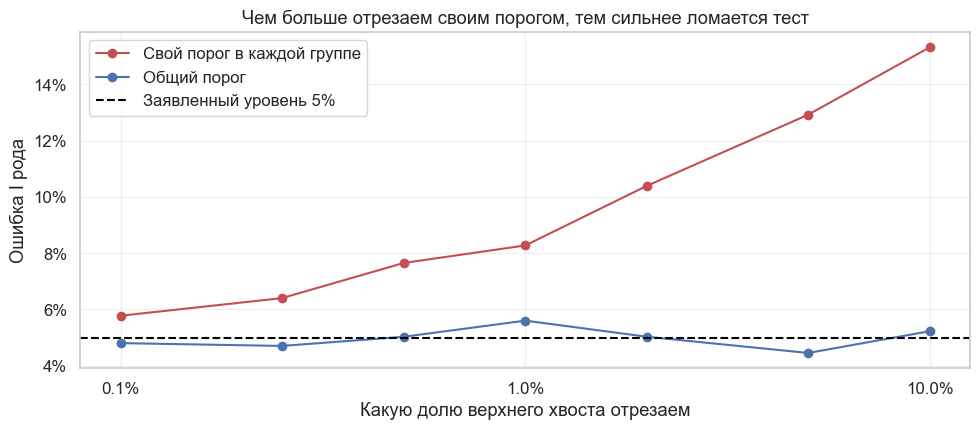

In [4]:
rng = np.random.default_rng(42)
tail_shares = np.array([0.001, 0.0025, 0.005, 0.01, 0.02, 0.05, 0.1])
per_group_fpr, pooled_fpr = [], []
for share in tail_shares:
    _, y_c = generate_revenue(rng, (4_000, 1_000))
    _, y_t = generate_revenue(rng, (4_000, 1_000))
    q_c = np.quantile(y_c, 1 - share, axis=1, keepdims=True)
    q_t = np.quantile(y_t, 1 - share, axis=1, keepdims=True)
    q_pooled = np.quantile(np.hstack([y_c, y_t]), 1 - share, axis=1, keepdims=True)
    for store, mask_c, mask_t in ((per_group_fpr, y_c <= q_c, y_t <= q_t), (pooled_fpr, y_c <= q_pooled, y_t <= q_pooled)):
        mean_c, var_c, n_c = masked_mean_var(y_c, mask_c)
        mean_t, var_t, n_t = masked_mean_var(y_t, mask_t)
        store.append(np.mean(z_pvalue(mean_t - mean_c, np.sqrt(var_c / n_c + var_t / n_t)) < ALPHA))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(tail_shares, per_group_fpr, 'o-', color=RED, label='Свой порог в каждой группе')
ax.plot(tail_shares, pooled_fpr, 'o-', color=BLUE, label='Общий порог')
ax.axhline(ALPHA, color='black', linestyle='--', label='Заявленный уровень 5%')
ax.set_xscale('log')
ax.set_xticks([0.001, 0.01, 0.1])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_xlabel('Какую долю верхнего хвоста отрезаем')
ax.set_ylabel('Ошибка I рода')
ax.set_title('Чем больше отрезаем своим порогом, тем сильнее ломается тест')
ax.legend()
plt.tight_layout()
plt.show()


#### Общий порог чинит A/A, но не A/B

Один порог на обе группы почти возвращает ошибку I рода к 5%. Но посмотрите на правый график: оценка эффекта занижена на четверть и больше. Причина одна для всех таких вариантов. **Удаление по значению метрики во время теста — это отбор по тому, на что повлияло воздействие.** В тесте выручка выросла, поэтому за порог уходит больше пользователей, и сравниваются уже разные наборы людей. Вдобавок эффект в хвосте просто отрезается.

Это относится и к порогу, посчитанному на предпериоде, если применять его к метрике во время теста: A/A почти в порядке, а эффект занижен так же. Сама по себе фиксация порога проблему не решает.

Корректные варианты:

* **Исключить пользователей по их поведению до теста.** Отбираем по значению на предпериоде, которое воздействие изменить не могло. Оценка почти не смещена, но это эффект на оставшихся пользователях.
* **Винзоризовать порогом с предпериода.** Значения выше порога не удаляются, а заменяются на порог: $\min(Y, q)$. Никого не выкидываем, состав групп не меняется, ошибка I рода корректна, а мощность немного выше, чем без очистки. Смещение остаётся, но оно меньше, и у него ясный смысл: это эффект на ограниченную сверху метрику.

На данных с лёгкими хвостами выигрыша может и не быть, поэтому эффект очистки стоит проверять на A/A- и A/B-симуляциях на своих данных. У новых пользователей нет предпериода, для них порог и правило заранее задаются отдельно.


### [Стратификация](https://habr.com/ru/companies/X5Tech/articles/596279/)


Стратификация снижает дисперсию за счёт дополнительной информации о пользователях.

Для понимания стратификации введём несколько определений:

* **Популяция** – все пользователи (или объекты), на которых мы можем повлиять экспериментом. Например, 10 тысяч активных пользователей интернет-магазина.
* **Ковариата** – метрика, которая:
    * коррелирует с целевой метрикой;
    * может быть измерена до начала эксперимента;
    * не зависит от воздействия.

  Для экспериментов с людьми это пол, возраст, город, операционная система. Для магазинов — торговая площадь или режим работы.
* **Страты** – непересекающиеся подмножества популяции, каждое со своим набором значений ковариат.

Дисперсия метрики раскладывается на сумму дисперсии *внутри* страт и дисперсии *между* стратами (закон полной дисперсии):

$$
\sigma^2 = \sum_{k=1}^K w_k \sigma_k^2 + \sum_{k=1}^K w_k (\mu_k - \mu)^2
$$

Стратификация **убирает вторую часть**, поэтому общая дисперсия оценки снижается. Есть два подхода: стратифицированное сэмплирование и постстратификация. Посчитаем оба на примере двух равных страт со средними 2000 и 3000.


#### Стратифицированное сэмплирование

**Стратифицированное сэмплирование (пред-стратификация)** – способ формировать контрольную и экспериментальную группы так, чтобы доли страт в них были равны долям страт в популяции. Для этого определяем нужное число представителей каждой страты и случайно отбираем их из неё.

<br></br>

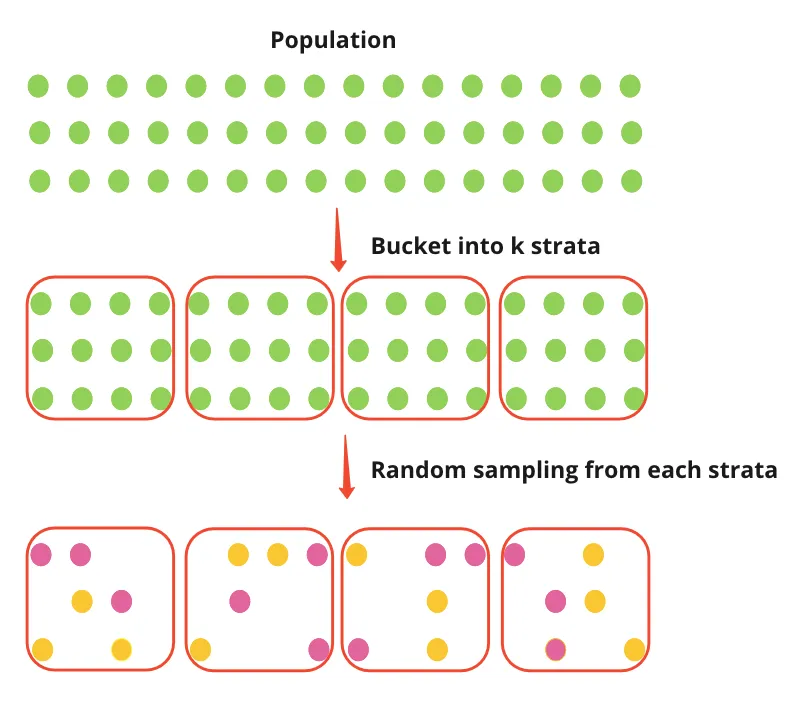


Дисперсия: 640,625 = 390,625 (внутри страт) + 250,000 (между стратами)
Расчётный объём выборки на группу: 1006



                                       Ошибка I рода  Мощность  SD оценки  Средняя SE
Случайно, обычное среднее                      0.048     0.791     35.674      35.674
Страт. сэмплирование, обычное среднее          0.012     0.854     27.518      35.685
Страт. сэмплирование, страт. среднее           0.054     0.952     28.241      27.878
Постстратификация                              0.052     0.946     28.013      27.862


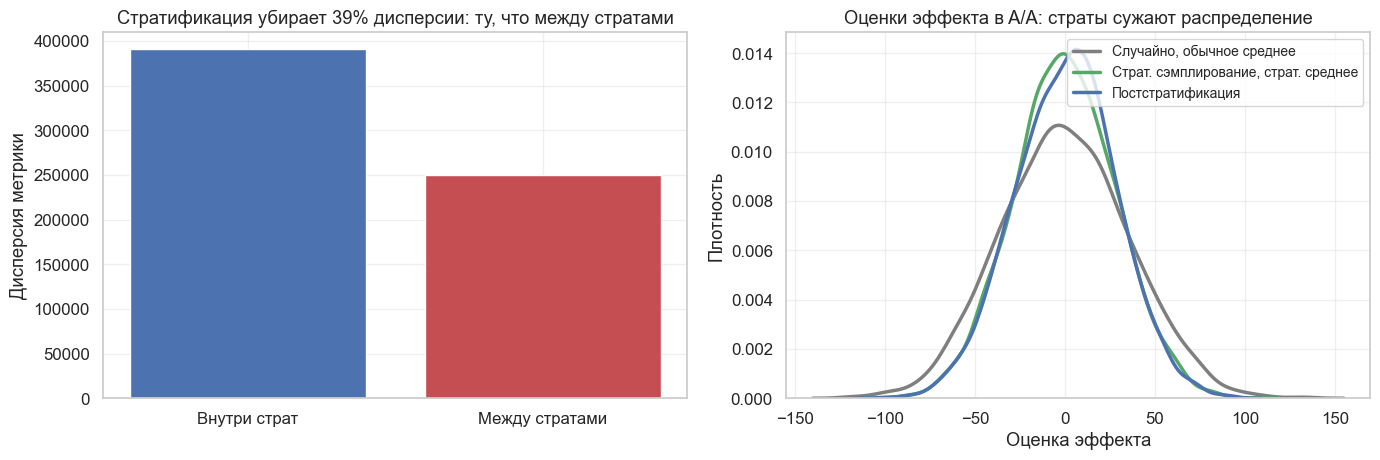

In [5]:
STRAT_CONFIG = {
    "alpha": ALPHA,
    "beta": 0.2,
    "effect": 100.0,
    "weights": (0.5, 0.5),  # доли страт в популяции
    "means": (2_000.0, 3_000.0),
    "stds": (625.0, 625.0),
}
strat_weights = np.array(STRAT_CONFIG["weights"])
strat_means = np.array(STRAT_CONFIG["means"])
strat_stds = np.array(STRAT_CONFIG["stds"])

# Общая дисперсия метрики: среднее дисперсий внутри страт + разброс средних между стратами
overall_mean = strat_weights @ strat_means
var_within = strat_weights @ strat_stds ** 2
var_between = strat_weights @ (strat_means - overall_mean) ** 2
var_total = var_within + var_between

z_sum = stats.norm.ppf(1 - STRAT_CONFIG["alpha"] / 2) + stats.norm.ppf(1 - STRAT_CONFIG["beta"])
strat_sample_size = int(np.ceil(2 * z_sum ** 2 * var_total / STRAT_CONFIG["effect"] ** 2))
print(f'Дисперсия: {var_total:,.0f} = {var_within:,.0f} (внутри страт) + {var_between:,.0f} (между стратами)')
print(f'Расчётный объём выборки на группу: {strat_sample_size}\n')


def generate_group(rng: np.random.Generator, size: tuple[int, int], stratified: bool, effect: float = 0.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует метрику и принадлежность к первой страте для группы с фиксированными или случайными долями страт."""
    if stratified:
        in_first = np.broadcast_to(np.arange(size[1]) < round(size[1] * strat_weights[0]), size)
    else:
        in_first = rng.random(size) < strat_weights[0]
    means = np.where(in_first, strat_means[0], strat_means[1])
    stds = np.where(in_first, strat_stds[0], strat_stds[1])
    return rng.normal(means + effect, stds), in_first


def plain_estimate(y: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Возвращает обычное среднее и выборочную дисперсию метрики."""
    return y.mean(axis=1), y.var(axis=1, ddof=1)


def strat_estimate(y: np.ndarray, in_first: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Возвращает стратифицированное среднее и взвешенную дисперсию внутри страт."""
    mean_one, var_one, _ = masked_mean_var(y, in_first)
    mean_two, var_two, _ = masked_mean_var(y, ~in_first)
    return (strat_weights[0] * mean_one + strat_weights[1] * mean_two,
            strat_weights[0] * var_one + strat_weights[1] * var_two)


def simulate_strat(n: int, n_simulations: int = 4_000, batch: int = 500) -> dict[str, dict[str, np.ndarray]]:
    """Сравнивает способы формирования групп и оценки среднего на A/A и A/B."""
    rng = np.random.default_rng(42)
    # Название: (стратифицированное сэмплирование, стратифицированное среднее)
    schemes = {
        'Случайно, обычное среднее': (False, False),
        'Страт. сэмплирование, обычное среднее': (True, False),
        'Страт. сэмплирование, страт. среднее': (True, True),
        'Постстратификация': (False, True),
    }
    result = {name: {'aa': [], 'ab': [], 'delta': [], 'se': []} for name in schemes}
    for _ in range(n_simulations // batch):
        for key, effect in (('aa', 0.0), ('ab', STRAT_CONFIG['effect'])):
            for name, (stratified, use_strat_mean) in schemes.items():
                y_c, first_c = generate_group(rng, (batch, n), stratified)
                y_t, first_t = generate_group(rng, (batch, n), stratified, effect)
                mean_c, var_c = strat_estimate(y_c, first_c) if use_strat_mean else plain_estimate(y_c)
                mean_t, var_t = strat_estimate(y_t, first_t) if use_strat_mean else plain_estimate(y_t)
                delta, se = mean_t - mean_c, np.sqrt((var_c + var_t) / n)
                result[name][key].append(z_pvalue(delta, se) < ALPHA)
                if key == 'aa':
                    result[name]['delta'].append(delta)
                    result[name]['se'].append(se)
    return {name: {key: np.concatenate(values) for key, values in row.items()} for name, row in result.items()}


strat_results = simulate_strat(strat_sample_size)
print(pd.DataFrame({
    name: {
        'Ошибка I рода': row['aa'].mean(),
        'Мощность': row['ab'].mean(),
        'SD оценки': row['delta'].std(),
        'Средняя SE': row['se'].mean(),
    } for name, row in strat_results.items()
}).T.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(['Внутри страт', 'Между стратами'], [var_within, var_between], color=[BLUE, RED])
axes[0].set_title(f'Стратификация убирает {var_between / var_total:.0%} дисперсии: ту, что между стратами')
axes[0].set_ylabel('Дисперсия метрики')
styles = {'Случайно, обычное среднее': GRAY, 'Страт. сэмплирование, страт. среднее': GREEN, 'Постстратификация': BLUE}
for name, color in styles.items():
    sns.kdeplot(strat_results[name]['delta'], ax=axes[1], label=name, color=color, linewidth=2.5)
axes[1].set_title('Оценки эффекта в A/A: страты сужают распределение')
axes[1].set_xlabel('Оценка эффекта')
axes[1].set_ylabel('Плотность')
axes[1].legend(loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()


Стратифицированное сэмплирование сильно уменьшило вероятности ошибок I и II рода, но это не совсем тот тест, который мы хотели. Мы планировали уровень значимости 0.05, а фактическая ошибка I рода равна 0.013. Распределение оценок эффекта стало уже: его реальное стандартное отклонение равно 27.5. Но t-тест не знает, что группы собраны не случайно, и считает завышенную стандартную ошибку (35.7). Вернуть тест на нужный уровень значимости поможет стратифицированное среднее.


#### Стратифицированное среднее

Оно вычисляется как взвешенная сумма средних каждой страты, где веса – доли страт в популяции.

Пусть $Y$ — целевая метрика, $k$ — индекс страты, $w_k$ — доля страты $k$ в популяции, $\bar{Y}_k$ — выборочное среднее метрики в страте $k$. Тогда стратифицированное среднее равно

$$
\bar{Y}_{strat} = \sum_{k=1}^K w_k \bar{Y}_k
$$

Обратим внимание на два свойства.

* При стратифицированном сэмплировании ($n_k = w_k n$) стратифицированное среднее совпадает с выборочным:

$$
\bar{Y}_{strat} = \sum_{k=1}^K w_k \bar{Y}_k = \sum_{k=1}^K w_k \frac{1}{n_k} \sum_{j=1}^{n_{k}} Y_{kj} = \sum_{k=1}^K \frac{n_k}{n} \frac{1}{n_k} \sum_{j=1}^{n_{k}} Y_{kj} = \frac{1}{n} \sum_{k=1}^K \sum_{j=1}^{n_{k}} Y_{kj} = \bar{Y}
$$

* Обычное и стратифицированное средние — несмещённые оценки одной и той же величины $\mu$. Для стратифицированного среднего при случайном сэмплировании это верно, если в каждую страту попало хотя бы одно наблюдение:

$$
\mathbb{E}(\bar{Y}) = \frac{1}{n} \sum_{k=1}^K \sum_{j=1}^{n_{k}} \mathbb{E} (Y_{kj}) = \mu, \qquad
\mathbb{E}(\bar{Y}_{strat}) = \sum_{k=1}^K w_k \mathbb{E}(\bar{Y}_{k}) = \sum_{k=1}^K w_k \mu_{k} = \mu
$$

Различаются они **дисперсией**. Для стратифицированного среднего при $n_k = w_k n$

$$
\mathbb{V}(\bar{Y}_{strat}) = \frac{1}{n} \sum_{k=1}^K w_k \sigma_k^2
$$

Подставив оценки $\hat{\sigma}_k^2$, получим статистику теста. При большом $n$ она приблизительно нормальна:

$$
t = \frac{\bar{Y}_{strat, B} - \bar{Y}_{strat, A}}{\sqrt{\hat{\mathbb{V}}(\bar{Y}_{strat, A}) + \hat{\mathbb{V}}(\bar{Y}_{strat, B})}} \approx \mathcal{N}(0, 1)
$$

С такой статистикой ошибка I рода в таблице выше вернулась к 0.054, а мощность выросла с 0.791 до 0.952. Под стратификацией обычно и понимают сочетание стратифицированного сэмплирования и стратифицированного среднего.


#### Постстратификация

**Постстратификация** – подход, при котором группы формируются случайно, а для оценки среднего используется **стратифицированное среднее**. Он нужен, когда управлять составом групп нельзя, и на практике применяется чаще: достаточно знать страту каждого пользователя на момент анализа.

Запишем дисперсии среднего для трёх схем:

$$
\mathbb{V}_{rand}(\bar{Y}) = \frac{1}{n} \sum_k w_k \sigma_k^2 + \frac{1}{n} \sum_k w_k (\mu_k - \mu)^2, \qquad
\mathbb{V}_{strat}(\bar{Y}_{strat}) = \frac{1}{n} \sum_k w_k \sigma_k^2
$$

$$
\mathbb{V}_{post}(\bar{Y}_{strat}) \approx \mathbb{V}_{strat}(\bar{Y}_{strat}) + \frac{1}{n^2} \sum_k (1 - w_k) \sigma_k^2
$$

Плата за случайный состав групп имеет порядок $1/n^2$, а выигрыш — $1/n$. Поэтому на больших выборках постстратификация почти не уступает стратификации, как и в нашей таблице (0.052 и 0.946). Обычно

$$
\mathbb{V}_{strat}(\bar{Y}_{strat}) \le \mathbb{V}_{post}(\bar{Y}_{strat}) \le \mathbb{V}_{rand}(\bar{Y})
$$

но правое неравенство не гарантировано: при малых $n$, слабых различиях между стратами или большом их числе постстратификация может оказаться хуже обычного среднего. На практике также следите, чтобы страты были определены **до** теста, чтобы воздействие не могло перевести пользователя из страты в страту, а в каждой группе были представители всех страт.

<br></br>

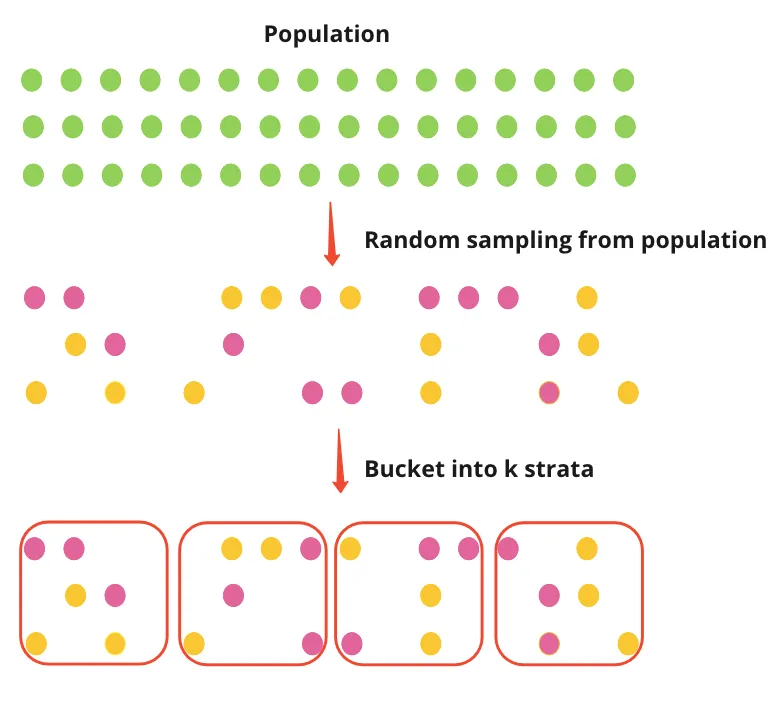

**Попробуйте сами.** Установите разнос страт 0, $n$ = 20 и увеличьте число страт: постстратификация станет хуже случайного разбиения.


In [6]:
def strat_variance_demo(between_gap: float = 1000.0, n: int = 1000, strat_std: float = 625.0, n_strata: int = 2) -> None:
    """Сравнивает теоретические дисперсии среднего при случайном разбиении, стратификации и постстратификации."""
    weights = np.full(n_strata, 1 / n_strata)
    means = np.linspace(-between_gap / 2, between_gap / 2, n_strata)
    between = weights @ means ** 2
    v_strat = strat_std ** 2 / n
    v_rand = v_strat + between / n
    v_post = v_strat + (1 - weights).sum() * strat_std ** 2 / n ** 2

    fig, ax = plt.subplots(figsize=(9, 3.2))
    labels = ['Случайное разбиение', 'Постстратификация', 'Стратифицированное сэмплирование']
    values = np.array([v_rand, v_post, v_strat])[::-1]
    bars = ax.barh(labels[::-1], values, color=[GREEN, BLUE, GRAY])
    ax.bar_label(bars, labels=[f'{v / v_rand:.1%} от случайного' for v in values], padding=4)
    ax.set_xlim(0, values.max() * 1.35)
    ax.set_xlabel('Дисперсия выборочного среднего')
    ax.set_title(f'n = {n}, страт: {n_strata}')
    plt.tight_layout()
    plt.show()


interact(strat_variance_demo,
         between_gap=FloatSlider(value=1000, min=0, max=3000, step=100, description='Разнос страт'),
         n=IntSlider(value=1000, min=20, max=2000, step=20, description='n'),
         strat_std=FloatSlider(value=625, min=100, max=1500, step=25, description='σ в страте'),
         n_strata=IntSlider(value=2, min=2, max=20, step=1, description='Страт'));


### [Бакетизация](https://habr.com/ru/articles/815331/)


**Бакетизация** — случайное разбиение пользователей на подгруппы (бакеты), которые затем анализируются как отдельные наблюдения. **Это единственный метод в разделе, который сам по себе не уменьшает дисперсию оценки эффекта.** Дисперсия среднего по бакету в $N/M$ раз меньше дисперсии пользователя, но и наблюдений стало в $N/M$ раз меньше, так что стандартная ошибка не меняется. Зато сильно ускоряются вычисления.

**Процесс бакетизации**

1. Назначаем каждому из $N$ независимых пользователей случайный номер бакета от 1 до $M$ ($M \le N$), обычно хешированием с отдельной солью. Один пользователь попадает только в один бакет.
2. Для каждого бакета считаем значение метрики: среднее, а для метрики отношения — сумму числителя, делённую на сумму знаменателя.
3. Проводим анализ на бакетах как на независимых наблюдениях.

Проверим, что происходит с ошибкой I рода и мощностью на скошенной метрике.


       Ошибка I рода  Мощность
20000          0.052     0.382
10             0.056     0.352
20             0.052     0.366
50             0.052     0.374
100            0.053     0.374
200            0.052     0.378
500            0.052     0.376
1000           0.052     0.378
5000           0.052     0.380


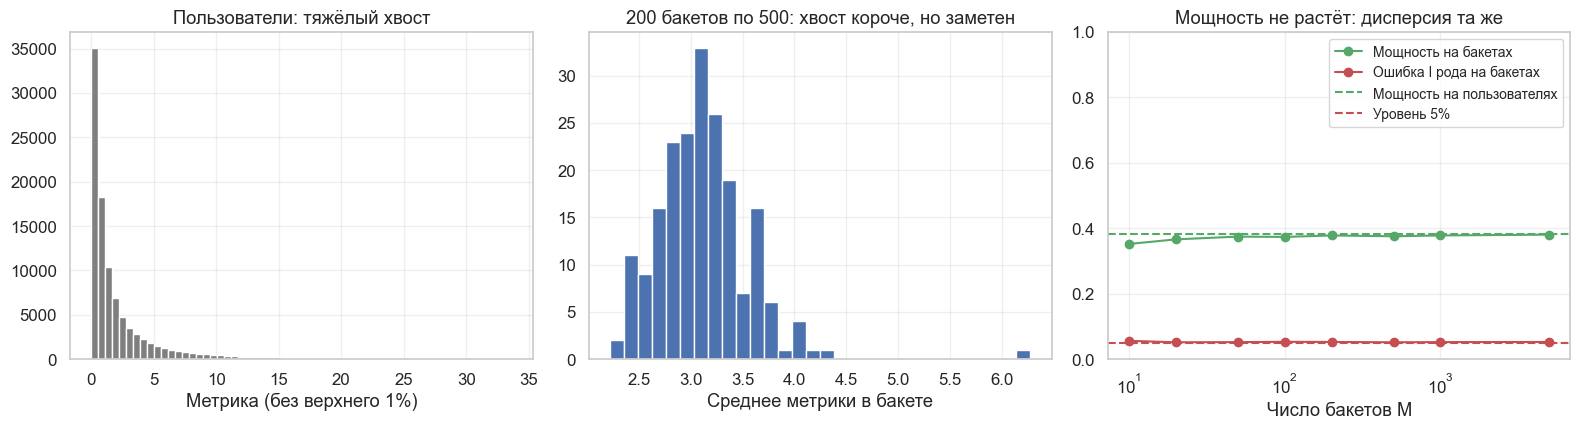

In [7]:
BUCKET_CONFIG = {
    "n_simulations": 2_000,
    "n_users": 20_000,  # на группу
    "lift": 1.05,
    "bucket_counts": [10, 20, 50, 100, 200, 500, 1_000, 5_000],
}


def simulate_buckets(n_simulations: int, n_users: int, lift: float, bucket_counts: list[int], batch: int = 100) -> pd.DataFrame:
    """Сравнивает t-тест на пользователях и на бакетах по ошибке I рода и мощности."""
    rng = np.random.default_rng(42)
    rejected = {count: {'aa': [], 'ab': []} for count in [n_users] + bucket_counts}
    for _ in range(n_simulations // batch):
        control = rng.lognormal(0, 1.5, (batch, n_users))
        pilot = rng.lognormal(0, 1.5, (batch, n_users))
        for count in rejected:
            # Пользователи i.i.d., поэтому равные куски массива ничем не хуже случайного разбиения по хешу
            buckets_c = control.reshape(batch, count, -1).mean(axis=2)
            buckets_t = pilot.reshape(batch, count, -1).mean(axis=2)
            rejected[count]['aa'].append(stats.ttest_ind(buckets_c, buckets_t, axis=1).pvalue < ALPHA)
            rejected[count]['ab'].append(stats.ttest_ind(buckets_c, buckets_t * lift, axis=1).pvalue < ALPHA)
    return pd.DataFrame({count: {key: np.concatenate(values).mean() for key, values in row.items()}
                         for count, row in rejected.items()}).T.rename(columns={'aa': 'Ошибка I рода', 'ab': 'Мощность'})


bucket_table = simulate_buckets(**BUCKET_CONFIG)
print(bucket_table.round(3).to_string())

user_level = bucket_table.loc[BUCKET_CONFIG['n_users']]
per_bucket = bucket_table.drop(index=BUCKET_CONFIG['n_users'])
rng = np.random.default_rng(42)
users = rng.lognormal(0, 1.5, 100_000)
bucket_means = users.reshape(200, -1).mean(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(users[users < np.quantile(users, 0.99)], bins=60, color=GRAY)
axes[0].set_title('Пользователи: тяжёлый хвост')
axes[0].set_xlabel('Метрика (без верхнего 1%)')
axes[1].hist(bucket_means, bins=30, color=BLUE)
axes[1].set_title('200 бакетов по 500: хвост короче, но заметен')
axes[1].set_xlabel('Среднее метрики в бакете')
axes[2].plot(per_bucket.index, per_bucket['Мощность'], 'o-', color=GREEN, label='Мощность на бакетах')
axes[2].plot(per_bucket.index, per_bucket['Ошибка I рода'], 'o-', color=RED, label='Ошибка I рода на бакетах')
axes[2].axhline(user_level['Мощность'], color=GREEN, linestyle='--', label='Мощность на пользователях')
axes[2].axhline(ALPHA, color=RED, linestyle='--', label='Уровень 5%')
axes[2].set_xscale('log')
axes[2].set_ylim(0, 1)
axes[2].set_xlabel('Число бакетов M')
axes[2].set_title('Мощность не растёт: дисперсия та же')
axes[2].legend(fontsize=10)
plt.tight_layout()
plt.show()


Мощность на бакетах практически та же, что на пользователях, и не превышает её: чудес нет. Заметно хуже становится только при очень малом числе бакетов, потому что растёт критическое значение $t$-распределения. Распределение средних бакетов гораздо ближе к нормальному, чем у пользователей, но при тяжёлом хвосте в бакете должно быть много пользователей.

Главная польза проявляется там, где вычисления дорогие. Например, в бутстрепе ([лекция 1.01](<../01. Статистика в Python. Бутстрап/lecture.ipynb>)) вместо миллиона значений нужно ресэмплировать тысячу. Обе оценки SE близки к теоретической, разница между ними объясняется шумом на тяжёлом хвосте.


In [8]:
rng = np.random.default_rng(42)
n_users, n_buckets = 1_000_000, 1_000
users = rng.lognormal(0, 1.5, n_users)
bucket_means = users.reshape(n_buckets, -1).mean(axis=1)

start = time.perf_counter()
raw_boot = np.array([users[rng.integers(0, n_users, n_users)].mean() for _ in range(200)])
raw_time = (time.perf_counter() - start) * 5  # пересчёт на 1000 итераций

start = time.perf_counter()
bucket_boot = bucket_means[rng.integers(0, n_buckets, (1_000, n_buckets))].mean(axis=1)
bucket_time = time.perf_counter() - start

print(f'Пользователи: {raw_time:.2f} с на 1000 итераций, SE среднего {raw_boot.std(ddof=1):.4f}')
print(f'Бакеты:       {bucket_time:.2f} с на 1000 итераций, SE среднего {bucket_boot.std(ddof=1):.4f}')
print(f'Теоретическая SE: {np.sqrt((np.exp(1.5 ** 2) - 1) * np.exp(2 * 0 + 1.5 ** 2) / n_users):.4f}')
print(f'Ускорение на этой машине: примерно в {raw_time / bucket_time:.0f} раз')


Пользователи: 11.12 с на 1000 итераций, SE среднего 0.0082
Бакеты:       0.01 с на 1000 итераций, SE среднего 0.0098
Теоретическая SE: 0.0090
Ускорение на этой машине: примерно в 1935 раз


**Попробуйте сами.** Посмотрите, сколько пользователей должно быть в бакете, чтобы распределение его среднего стало близко к нормальному при разной тяжести хвоста.


In [9]:
def bucket_demo(n_buckets: int = 100, sigma: float = 1.5) -> None:
    """Показывает, как с ростом размера бакета распределение его среднего приближается к нормальному."""
    rng = np.random.default_rng(42)
    users = rng.lognormal(0, sigma, 200_000)
    means = users[: 200_000 // n_buckets * n_buckets].reshape(n_buckets, -1).mean(axis=1)
    grid = np.linspace(means.min(), means.max(), 200)

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(means, bins=min(50, n_buckets // 2), density=True, color=BLUE, alpha=0.75)
    ax.plot(grid, stats.norm.pdf(grid, means.mean(), means.std(ddof=1)), color=RED, label='Нормальное распределение')
    ax.set_title(f'{n_buckets} бакетов по {200_000 // n_buckets:,} пользователей, скошенность {stats.skew(means):.2f}')
    ax.set_xlabel('Среднее метрики в бакете')
    ax.legend()
    plt.tight_layout()
    plt.show()


interact(bucket_demo,
         n_buckets=IntSlider(value=100, min=20, max=5000, step=20, description='Бакетов'),
         sigma=FloatSlider(value=1.5, min=0.5, max=2.5, step=0.1, description='Хвост (σ)'));


Из бакетизации можно получить и снижение дисперсии, если назначать бакеты не случайно, а по информации о пользователях:

1. Делить по децилям и проводить [децильный анализ](https://vk.com/@sciensespss-decilnyi-metod-ili-sokraschenie-dispersii).
2. Назначать бакеты по ковариатам, которые не зависят от воздействия и сильно ковариируют с метрикой. По сути, это уже стратификация.


### [Линеаризация](https://www.researchgate.net/publication/322969314_Consistent_Transformation_of_Ratio_Metrics_for_Efficient_Online_Controlled_Experiments)


Метрика отношения (CTR, средний чек, клики на сессию) считается как отношение сумм, поэтому её наблюдения — это показы или заказы, а не пользователи. Один пользователь даёт много зависимых наблюдений, и обычный t-тест применять нельзя ([лекция 1.02](<../02. Введение в тестирование гипотез и дизайн AB/lecture.ipynb>)). Дисперсию можно посчитать дельта-методом ([практика 1.П1](<../../Практический блок/01. ЦПТ. Дельта метод. Построение оценок и доверительных интервалов/practice.ipynb>)), но с ним не работают методы вроде CUPED, которым нужна метрика на уровне пользователя.

**Линеаризация** ([Budylin et al., 2018](https://doi.org/10.1145/3159652.3159699)) решает именно эту задачу: превращает метрику отношения в **пользовательскую метрику**.

**Важно:** сама по себе линеаризация **не снижает дисперсию** и не делает тест мощнее дельта-метода, их p-value практически совпадают. Её ценность в том, что поверх новой метрики можно применить t-тест, CUPED и другие методы снижения дисперсии.

Для метрики отношения $\mathcal{R} = \frac{\sum_{u \in U} Y(u)}{\sum_{u \in U} X(u)}$ линеаризованная метрика равна

$$
Lin(u) = Y(u) - \mathcal{R}^{ctrl} X(u), \text{ где } \mathcal{R}^{ctrl} - \text{значение метрики отношения в контрольной группе}
$$

Посчитав $Lin(u)$ для каждого пользователя в обеих группах, сравниваем средние обычным t-тестом. Средняя метрика в контроле равна нулю, а разница средних связана с эффектом так:

$$
\overline{Lin}^{\,test} - \overline{Lin}^{\,ctrl} = \bar{X}^{test} \left( \mathcal{R}^{test} - \mathcal{R}^{ctrl} \right)
$$

Отсюда следуют две практические детали: знак эффекта всегда совпадает со знаком изменения исходной метрики, а чтобы получить эффект в единицах метрики отношения, разницу нужно поделить на $\bar{X}^{test}$. По той же причине MDE для линеаризованной метрики равен MDE метрики отношения, умноженному на средний знаменатель.

**Линеаризация с весами.** Пользователи с большим знаменателем могут вносить в метрику много шума. Чтобы снизить их влияние, наблюдения можно перевзвесить, например, на корень из знаменателя:

$$
\mathcal{R}_{rew} = \frac{\sum_u \sqrt{X(u)} \times \frac{Y(u)}{X(u)}}{\sum_u \sqrt{X(u)}}, \qquad
Lin_{rew}(u) = \sqrt{X(u)} \left( \frac{Y(u)}{X(u)} - \mathcal{R}_{rew}^{ctrl} \right)
$$

Это уже другая метрика с другими весами пользователей: такой вариант подходит для проверки гипотезы, но его эффект не равен эффекту на исходную метрику отношения.

Проверим всё это на CTR: у пользователей разная активность и разная склонность кликать, а воздействие поднимает CTR на 5%.


                              Ошибка I рода  Мощность
По показам, клики независимы          0.191     0.586
Среднее CTR пользователей             0.048     0.260
Дельта-метод                          0.052     0.340
Линеаризация                          0.052     0.346
Линеаризация с весами                 0.046     0.384
Линеаризация + CUPED                  0.048     0.462


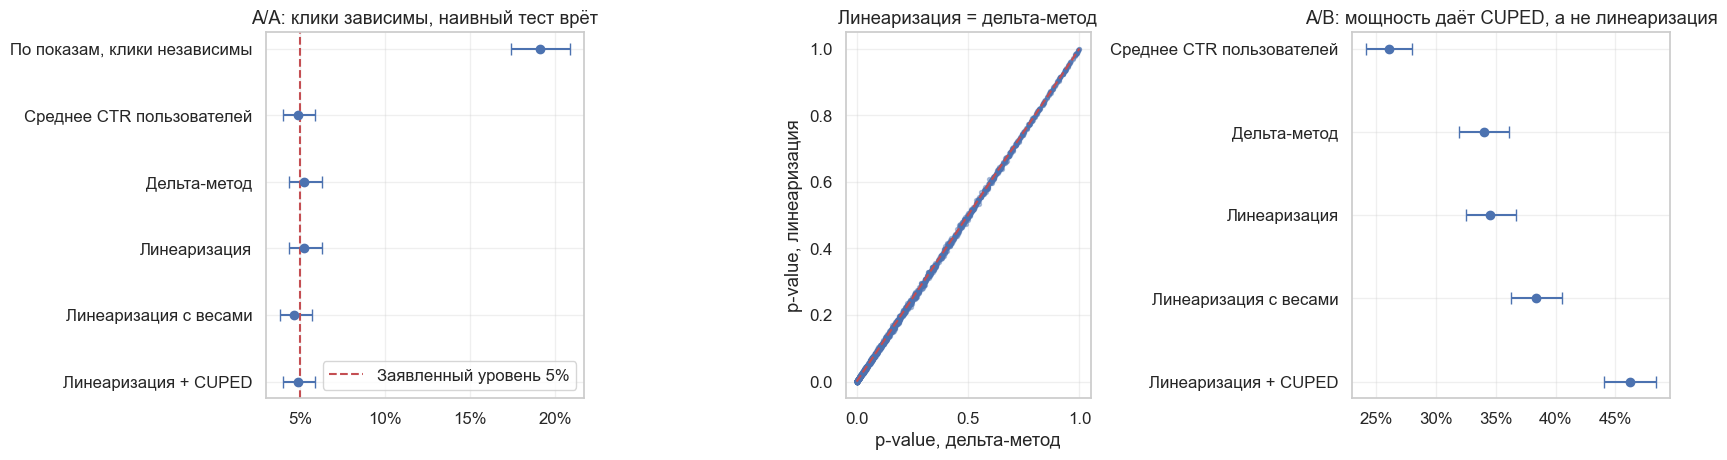

In [10]:
LIN_CONFIG = {
    "n_simulations": 2_000,
    "n_users": 3_000,
    "uplift": 0.05,  # рост CTR на 5%
}


def generate_ctr_data(rng: np.random.Generator, size: tuple[int, int], uplift: float = 0.0) -> dict[str, np.ndarray]:
    """Генерирует просмотры и клики пользователей до и во время эксперимента."""
    activity = rng.gamma(1.0, 12.0, size)  # у пользователей разная активность
    ctr = rng.beta(2, 18, size) * np.clip(1.6 - 0.03 * activity, 0.4, 1.6)  # и разная склонность кликать
    views_pre = 1 + rng.poisson(activity)
    views = 1 + rng.poisson(activity)
    return {
        'views_pre': views_pre,
        'clicks_pre': rng.binomial(views_pre, ctr),
        'views': views,
        'clicks': rng.binomial(views, np.minimum(ctr * (1 + uplift), 1)),
    }


def ratio_delta_var(views: np.ndarray, clicks: np.ndarray) -> np.ndarray:
    """Считает дисперсию ratio-метрики дельта-методом по пользовательским суммам."""
    n = views.shape[1]
    mean_x, mean_y = views.mean(axis=1, keepdims=True), clicks.mean(axis=1, keepdims=True)
    ratio = mean_y / mean_x
    return ((clicks - ratio * views) ** 2).sum(axis=1) / (n - 1) / (n * mean_x[:, 0] ** 2)


def ratio_tests(control: dict[str, np.ndarray], pilot: dict[str, np.ndarray]) -> dict[str, np.ndarray]:
    """Возвращает p-value разных критериев для метрики отношения."""
    x_c, y_c, x_t, y_t = control['views'], control['clicks'], pilot['views'], pilot['clicks']
    r_c = y_c.sum(axis=1, keepdims=True) / x_c.sum(axis=1, keepdims=True)
    r_t = y_t.sum(axis=1, keepdims=True) / x_t.sum(axis=1, keepdims=True)
    delta = (r_t - r_c)[:, 0]

    # Клики как независимые испытания: типичная ошибка
    se_naive = np.sqrt(r_c[:, 0] * (1 - r_c[:, 0]) / x_c.sum(axis=1) + r_t[:, 0] * (1 - r_t[:, 0]) / x_t.sum(axis=1))
    se_delta = np.sqrt(ratio_delta_var(x_c, y_c) + ratio_delta_var(x_t, y_t))

    lin_c, lin_t = y_c - r_c * x_c, y_t - r_c * x_t

    w_c, w_t = np.sqrt(x_c), np.sqrt(x_t)
    r_rew = ((w_c * y_c / x_c).sum(axis=1) / w_c.sum(axis=1))[:, None]
    rew_c, rew_t = (y_c - r_rew * x_c) / w_c, (y_t - r_rew * x_t) / w_t

    # CUPED поверх линеаризации: ковариата — та же линеаризованная метрика на предпериоде
    r_pre = control['clicks_pre'].sum(axis=1, keepdims=True) / control['views_pre'].sum(axis=1, keepdims=True)
    cov_c = control['clicks_pre'] - r_pre * control['views_pre']
    cov_t = pilot['clicks_pre'] - r_pre * pilot['views_pre']
    pooled_lin, pooled_cov = np.hstack([lin_c, lin_t]), np.hstack([cov_c, cov_t])
    centered_cov = pooled_cov - pooled_cov.mean(axis=1, keepdims=True)
    theta = ((pooled_lin * centered_cov).sum(axis=1) / (centered_cov ** 2).sum(axis=1))[:, None]

    return {
        'По показам, клики независимы': z_pvalue(delta, se_naive),
        'Среднее CTR пользователей': stats.ttest_ind(y_t / x_t, y_c / x_c, axis=1).pvalue,
        'Дельта-метод': z_pvalue(delta, se_delta),
        'Линеаризация': stats.ttest_ind(lin_t, lin_c, axis=1).pvalue,
        'Линеаризация с весами': stats.ttest_ind(rew_t, rew_c, axis=1).pvalue,
        'Линеаризация + CUPED': stats.ttest_ind(lin_t - theta * cov_t, lin_c - theta * cov_c, axis=1).pvalue,
    }


def simulate_ratio(n_simulations: int, n_users: int, uplift: float, batch: int = 200) -> dict[str, dict[str, np.ndarray]]:
    """Прогоняет A/A и A/B и собирает p-value всех критериев."""
    rng = np.random.default_rng(42)
    result: dict[str, dict[str, list]] = {'aa': {}, 'ab': {}}
    for _ in tqdm(range(n_simulations // batch), desc='Симуляции ratio-метрики'):
        for key, effect in (('aa', 0.0), ('ab', uplift)):
            control = generate_ctr_data(rng, (batch, n_users))
            pilot = generate_ctr_data(rng, (batch, n_users), effect)
            for name, pvalues in ratio_tests(control, pilot).items():
                result[key].setdefault(name, []).append(pvalues)
    return {key: {name: np.concatenate(values) for name, values in row.items()} for key, row in result.items()}


ratio_pvalues = simulate_ratio(**LIN_CONFIG)
print(pd.DataFrame({
    'Ошибка I рода': {name: np.mean(p < ALPHA) for name, p in ratio_pvalues['aa'].items()},
    'Мощность': {name: np.mean(p < ALPHA) for name, p in ratio_pvalues['ab'].items()},
}).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1.3, 1, 1.3]})
plot_rates(axes[0], {name: p < ALPHA for name, p in ratio_pvalues['aa'].items()}, 'A/A: клики зависимы, наивный тест врёт')
axes[1].scatter(ratio_pvalues['ab']['Дельта-метод'], ratio_pvalues['ab']['Линеаризация'], s=8, alpha=0.4, color=BLUE)
axes[1].plot([0, 1], [0, 1], color=RED, linestyle='--')
axes[1].set_title('Линеаризация = дельта-метод')
axes[1].set_xlabel('p-value, дельта-метод')
axes[1].set_ylabel('p-value, линеаризация')
correct = [name for name in ratio_pvalues['ab'] if name != 'По показам, клики независимы']
plot_rates(axes[2], {name: ratio_pvalues['ab'][name] < ALPHA for name in correct}, 'A/B: мощность даёт CUPED, а не линеаризация', None)
plt.tight_layout()
plt.show()


Что видно по результатам:

* Если считать показы независимыми, ошибка I рода равна 19.1%. Это главная проблема, которую решают дельта-метод и линеаризация.
* Линеаризация и дельта-метод совпадают: точки на среднем графике лежат на диагонали, мощность 0.345 и 0.340.
* Среднее CTR пользователей — корректный тест, но **другой метрики**: каждый пользователь в нём весит одинаково, а не пропорционально показам. Поэтому и мощность другая (0.261), а значение метрики может заметно отличаться от общего CTR.
* Линеаризация с весами на этих данных мощнее (0.384), но это свойство данных, а не гарантия.
* Настоящий выигрыш даёт CUPED поверх линеаризации: мощность 0.462.

Проверим формулу перехода к единицам метрики отношения:


In [11]:
rng = np.random.default_rng(7)
control = generate_ctr_data(rng, (1, 200_000))
pilot = generate_ctr_data(rng, (1, 200_000), LIN_CONFIG['uplift'])

ratio_c = control['clicks'].sum() / control['views'].sum()
ratio_t = pilot['clicks'].sum() / pilot['views'].sum()
lin_c = control['clicks'] - ratio_c * control['views']
lin_t = pilot['clicks'] - ratio_c * pilot['views']

print(f"Эффект на CTR:                     {ratio_t - ratio_c:.5f}")
print(f"Эффект на линеаризованной метрике: {lin_t.mean() - lin_c.mean():.5f}")
print(f"Он же, делённый на X̄ теста:        {(lin_t.mean() - lin_c.mean()) / pilot['views'].mean():.5f}")


Эффект на CTR:                     0.00466
Эффект на линеаризованной метрике: 0.06045
Он же, делённый на X̄ теста:        0.00466


### [Variance-Weighted Estimator](https://www.youtube.com/watch?v=jZNXthVqbrc)


**Variance-Weighted Estimator (VWE)** ([Liou, Taylor, 2020](https://doi.org/10.1145/3391403.3399542)) использует гетероскедастичность данных: одни пользователи шумные, другие стабильные. Метод даёт каждому наблюдению вес, тем меньший, чем больше его дисперсия. Дисперсия взвешенной оценки равна

$$
\mathbb{V}(\hat{\mu}) = \frac{\sum_i w_i^2 \sigma_i^2}{\left( \sum_i w_i \right)^2},
$$

и она минимальна при $w_i \propto 1 / \sigma_i^2$. Тогда $\mathbb{V}(\hat{\mu}) = 1 / \sum_i \sigma_i^{-2}$.

Настоящие $\sigma_i^2$ неизвестны, поэтому на практике:

1. Для каждого пользователя оцениваем дисперсию метрики **до эксперимента**, чтобы воздействие на неё не влияло.
2. Делим пользователей на страты по этой оценке (например, децили).
3. Считаем эффект и его дисперсию в каждой страте.
4. Объединяем эффекты с весами, обратно пропорциональными их дисперсиям.

**Важная оговорка.** VWE даёт взвешенный эффект, в котором стабильные пользователи важнее шумных. Если эффект у всех одинаков, это тот же эффект, что и средний. Если шумные пользователи реагируют иначе, оценка смещена относительно среднего эффекта на всю аудиторию. Авторы на реальных тестах Facebook получили снижение дисперсии примерно на 17% при смещении менее 2%, но проверять это нужно на своих данных.


Средний эффект на всю аудиторию: 0.03
                                          Ошибка I рода  Мощность  Оценка эффекта  SD оценки
Эффект одинаков у всех   Разница средних          0.050     0.698          0.0300     0.0123
                         VWE                      0.043     0.998          0.0302     0.0065
Шумные реагируют сильнее Разница средних          0.050     0.695          0.0300     0.0123
                         VWE                      0.043     0.728          0.0167     0.0065


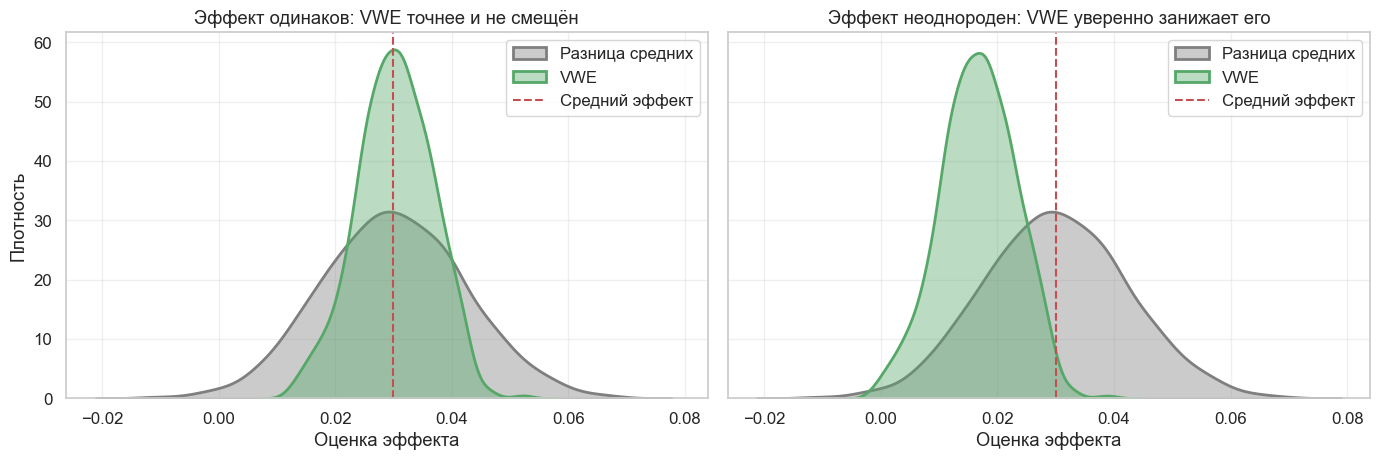

In [12]:
VWE_CONFIG = {
    "n_simulations": 1_000,
    "n_users": 2_000,  # на группу
    "effect": 0.03,
    "pre_days": 28,
    "exp_days": 14,
    "n_strata": 10,
}


def vwe_estimate(y: np.ndarray, is_pilot: np.ndarray, pre_var: np.ndarray, n_strata: int) -> tuple[np.ndarray, np.ndarray]:
    """Считает эффект по стратам предсказанной дисперсии и объединяет их с весами, обратными дисперсии."""
    order = np.argsort(pre_var, axis=1)
    y_sorted = np.take_along_axis(y, order, axis=1)
    pilot_sorted = np.take_along_axis(is_pilot, order, axis=1)
    weighted_sum, weight_sum = 0.0, 0.0
    for part_y, part_pilot in zip(np.array_split(y_sorted, n_strata, axis=1), np.array_split(pilot_sorted, n_strata, axis=1)):
        mean_t, var_t, n_t = masked_mean_var(part_y, part_pilot)
        mean_c, var_c, n_c = masked_mean_var(part_y, ~part_pilot)
        weight = 1 / (var_t / n_t + var_c / n_c)
        weighted_sum = weighted_sum + weight * (mean_t - mean_c)
        weight_sum = weight_sum + weight
    return weighted_sum / weight_sum, 1 / np.sqrt(weight_sum)


def simulate_vwe(n_simulations: int, n_users: int, effect: float, pre_days: int, exp_days: int, n_strata: int) -> dict[tuple[str, str], dict]:
    """Сравнивает обычную разницу средних и VWE при одинаковом и при неоднородном эффекте."""
    rng = np.random.default_rng(42)
    size = (n_simulations, 2 * n_users)
    is_pilot = np.broadcast_to(np.arange(2 * n_users) >= n_users, size)
    user_std = np.exp(rng.normal(0, 0.6, size))
    pre_var = user_std ** 2 * rng.chisquare(pre_days - 1, size) / (pre_days - 1)  # оценка по предпериоду
    noise = user_std * rng.normal(0, 1, size) / np.sqrt(exp_days)

    scenarios = {
        'Эффект одинаков у всех': np.full(size, effect),
        'Шумные реагируют сильнее': effect * user_std / user_std.mean(),
    }
    result = {}
    for name, user_effect in scenarios.items():
        for key, y in (('A/A', noise), ('A/B', noise + user_effect * is_pilot)):
            mean_t, var_t, n_t = masked_mean_var(y, is_pilot)
            mean_c, var_c, n_c = masked_mean_var(y, ~is_pilot)
            classic = mean_t - mean_c, np.sqrt(var_t / n_t + var_c / n_c)
            result[name, key] = {'Разница средних': classic, 'VWE': vwe_estimate(y, is_pilot, pre_var, n_strata)}
    return result


vwe_results = simulate_vwe(**VWE_CONFIG)
rows = {}
for scenario in ('Эффект одинаков у всех', 'Шумные реагируют сильнее'):
    for method in ('Разница средних', 'VWE'):
        delta_aa, se_aa = vwe_results[scenario, 'A/A'][method]
        delta_ab, se_ab = vwe_results[scenario, 'A/B'][method]
        rows[scenario, method] = {
            'Ошибка I рода': np.mean(z_pvalue(delta_aa, se_aa) < ALPHA),
            'Мощность': np.mean(z_pvalue(delta_ab, se_ab) < ALPHA),
            'Оценка эффекта': delta_ab.mean(),
            'SD оценки': delta_ab.std(),
        }
print(f"Средний эффект на всю аудиторию: {VWE_CONFIG['effect']}")
print(pd.DataFrame(rows).T.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True, sharey=True)
scenario_titles = {
    'Эффект одинаков у всех': 'Эффект одинаков: VWE точнее и не смещён',
    'Шумные реагируют сильнее': 'Эффект неоднороден: VWE уверенно занижает его',
}
for ax, (scenario, title) in zip(axes, scenario_titles.items()):
    for method, color in (('Разница средних', GRAY), ('VWE', GREEN)):
        sns.kdeplot(vwe_results[scenario, 'A/B'][method][0], ax=ax, color=color, fill=True, alpha=0.4, linewidth=2, label=method)
    ax.axvline(VWE_CONFIG['effect'], color=RED, linestyle='--', label='Средний эффект')
    ax.set_title(title)
    ax.set_xlabel('Оценка эффекта')
    ax.set_ylabel('Плотность')
    ax.legend()
plt.tight_layout()
plt.show()


Когда эффект одинаков у всех, VWE снижает стандартное отклонение оценки почти вдвое и не смещён. Когда шумные пользователи реагируют сильнее, ошибка I рода остаётся корректной: если эффекта нет, смещаться нечему. Но оценка эффекта занижена почти вдвое (0.017 вместо 0.03), а узкое распределение создаёт ложную уверенность. Поэтому VWE хорошо подходит для решения, катить ли изменение, и хуже для оценки его размера. Метод можно сочетать с CUPED, авторы сообщают о почти 50-процентном снижении дисперсии вместе.


### [CUPED](https://habr.com/ru/companies/X5Tech/articles/780270/)


**CUPED (Controlled-experiment Using Pre-Experiment Data)** ([Deng et al., 2013](https://doi.org/10.1145/2433396.2433413)) — высокоэффективный метод снижения дисперсии метрик. Его идея — вычесть из теста и контроля нечто такое, чтобы математическое ожидание разницы осталось прежним, а дисперсия уменьшилась.

Для этого нужна ковариата — метрика, скоррелированная с целевой и не зависящая от эксперимента. Чаще всего это значение той же метрики на периоде до эксперимента. Обозначим целевую метрику как $Y$, а ковариату как $X$.

Суть метода CUPED — в переходе от метрики $Y$ к метрике

$$
Y_{cuped} = Y - \theta (X - \bar{X}), \text{ где } \theta - \text{некоторое число, а } \bar{X} - \text{среднее ковариаты по обеим группам}
$$

Значения CUPED-метрики подаются в статистический критерий вместо исходных. Точечная оценка эффекта — разница средних CUPED-метрики в группах. При случайном распределении пользователей $\mathbb{E}(\bar{X}^{test}) = \mathbb{E}(\bar{X}^{ctrl})$, то есть в обеих группах в среднем вычитается одно и то же, и оценка эффекта не смещена. Оценка $\theta$ по тем же данным добавляет лишь пренебрежимо малое смещение.

Центрирование $X - \bar{X}$ на разницу средних не влияет, если $\theta$ в группах общий. Но оно сохраняет исходный уровень метрики, что нужно для относительного эффекта.

Посмотрим, как меняется дисперсия оценки среднего:

$$
\mathbb{V}(\overline{Y}_{cuped}) = \dfrac{\mathbb{V}\left(Y - \theta X\right)}{n} = \dfrac{\mathbb{V} (Y) - 2\theta\,\mathrm{cov}\left(Y,X\right) + \theta^2\mathbb{V} (X)}{n}
$$

Дисперсия квадратично зависит от $\theta$. Это парабола с точкой минимума

$$
\theta_0 = \frac{\mathrm{cov}(Y,X)}{\mathbb{V} (X)}
$$

Минимальная дисперсия равна

$$
\min\left(\mathbb{V} (\overline{Y}_{cuped})\right) = \mathbb{V} (\overline{Y}) \cdot \left(1 - \rho^2\right), \qquad \text{где } \rho = \frac{\mathrm{cov}(Y,X)} {\sqrt{\mathbb{V} (Y) \mathbb{V} (X)}}
$$

Значит, размер выборки сокращается в $1 / (1 - \rho^2)$ раз. Чем сильнее ковариата коррелирует с метрикой, тем больше выигрыш.

**Алгоритм применения CUPED**

1. Вычислить значения метрики $Y$ для каждого пользователя в обеих группах.
2. Вычислить значения ковариаты $X$ для каждого пользователя в обеих группах.
3. Вычислить $\theta = \frac{\mathrm{cov}(Y,X)}{\mathbb{V} (X)}$ по объединённым данным.
4. Для каждого пользователя вычислить $Y_{cuped} = Y - \theta (X - \bar{X})$.
5. Применить статистический тест к значениям CUPED-метрики.

**Новые пользователи.** Если у пользователя нет данных до эксперимента, ковариату заполняют одним и тем же правилом в обеих группах (например, средним или нулём). Оценка остаётся несмещённой, но для таких пользователей CUPED не даст выигрыша.


#### Симуляция


Дисперсия CUPED-метрики / исходной: 0.510
Теория 1 - ρ²:                      0.510


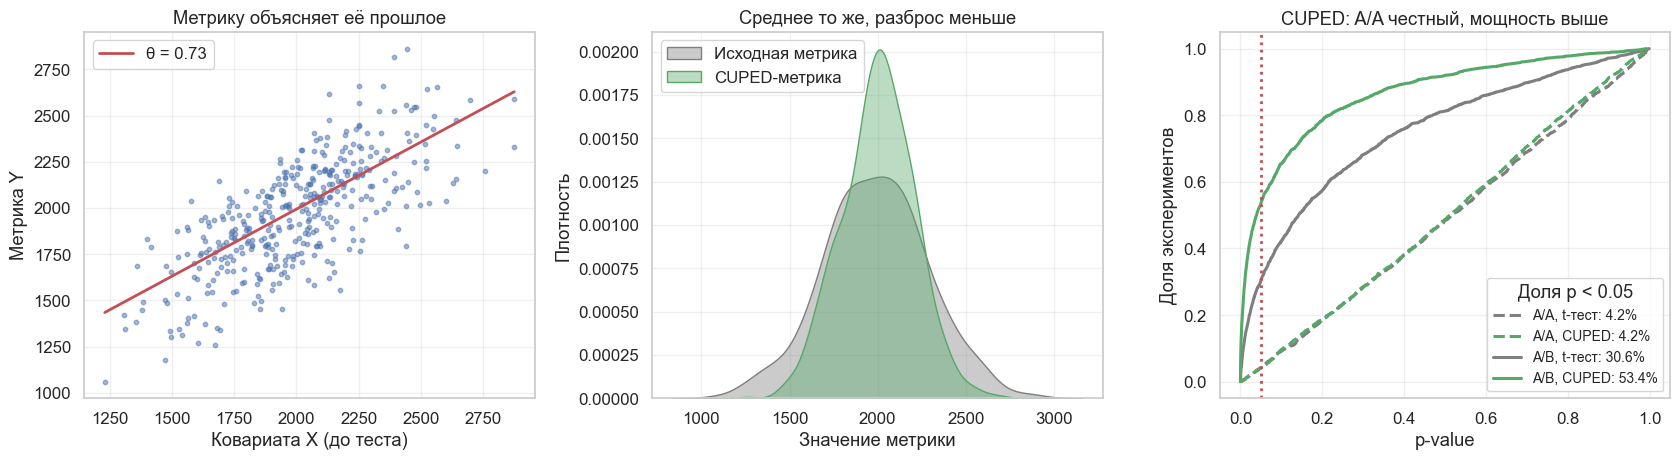

In [13]:
CUPED_CONFIG = {
    "n_simulations": 2_000,
    "sample_size": 1_000,
    "corr": 0.7,
    "effect": 20.0,
    "mean": 2_000.0,
    "sigma": 300.0,
}


def generate_metric_covariate(rng: np.random.Generator, size: tuple[int, int], corr: float, mean: float = 2_000.0,
                              sigma: float = 300.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует метрику и ковариату с заданной корреляцией."""
    covariate = rng.normal(0, 1, size)
    metric = corr * covariate + np.sqrt(1 - corr ** 2) * rng.normal(0, 1, size)
    return mean + sigma * metric, mean + sigma * covariate


def calculate_theta(metric: np.ndarray, covariate: np.ndarray) -> np.ndarray:
    """Считает коэффициент θ для CUPED по строкам."""
    cov_centered = covariate - covariate.mean(axis=1, keepdims=True)
    metric_centered = metric - metric.mean(axis=1, keepdims=True)
    return (cov_centered * metric_centered).sum(axis=1, keepdims=True) / (cov_centered ** 2).sum(axis=1, keepdims=True)


def apply_cuped(y_c: np.ndarray, x_c: np.ndarray, y_t: np.ndarray, x_t: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Считает CUPED-метрику обеих групп с общим θ и общим средним ковариаты."""
    pooled_x = np.hstack([x_c, x_t])
    theta = calculate_theta(np.hstack([y_c, y_t]), pooled_x)
    x_mean = pooled_x.mean(axis=1, keepdims=True)
    return y_c - theta * (x_c - x_mean), y_t - theta * (x_t - x_mean)


def plot_pvalue_ecdf(ax: plt.Axes, pvalues: dict[str, tuple[np.ndarray, str]]) -> None:
    """Рисует эмпирические функции распределения p-value: высота при α равна доле отклонений H0."""
    for name, (values, color) in pvalues.items():
        sorted_p = np.sort(values)
        style = '--' if 'A/A' in name else '-'
        ax.plot(sorted_p, np.arange(1, sorted_p.size + 1) / sorted_p.size, color=color, linestyle=style, linewidth=2.2,
                label=f'{name}: {np.mean(values < ALPHA):.1%}')
    ax.axvline(ALPHA, color=RED, linestyle=':', linewidth=2)
    ax.set_xlabel('p-value')
    ax.set_ylabel('Доля экспериментов')


rng = np.random.default_rng(42)
size = (CUPED_CONFIG['n_simulations'], CUPED_CONFIG['sample_size'])
params = (CUPED_CONFIG['corr'], CUPED_CONFIG['mean'], CUPED_CONFIG['sigma'])
y_c, x_c = generate_metric_covariate(rng, size, *params)
y_t, x_t = generate_metric_covariate(rng, size, *params)
y_e = y_t + CUPED_CONFIG['effect']

cuped_c, cuped_aa = apply_cuped(y_c, x_c, y_t, x_t)
cuped_c_ab, cuped_ab = apply_cuped(y_c, x_c, y_e, x_t)
cuped_pvalues = {
    'A/A, t-тест': (stats.ttest_ind(y_t, y_c, axis=1).pvalue, GRAY),
    'A/A, CUPED': (stats.ttest_ind(cuped_aa, cuped_c, axis=1).pvalue, GREEN),
    'A/B, t-тест': (stats.ttest_ind(y_e, y_c, axis=1).pvalue, GRAY),
    'A/B, CUPED': (stats.ttest_ind(cuped_ab, cuped_c_ab, axis=1).pvalue, GREEN),
}
print(f"Дисперсия CUPED-метрики / исходной: {cuped_c.var(axis=1).mean() / y_c.var(axis=1).mean():.3f}")
print(f"Теория 1 - ρ²:                      {1 - CUPED_CONFIG['corr'] ** 2:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(x_c[0, :400], y_c[0, :400], s=10, alpha=0.5, color=BLUE)
theta_line = calculate_theta(y_c[:1], x_c[:1])[0, 0]
grid = np.array([x_c[0, :400].min(), x_c[0, :400].max()])
axes[0].plot(grid, y_c[0].mean() + theta_line * (grid - x_c[0].mean()), color=RED, linewidth=2, label=f'θ = {theta_line:.2f}')
axes[0].set_title('Метрику объясняет её прошлое')
axes[0].set_xlabel('Ковариата X (до теста)')
axes[0].set_ylabel('Метрика Y')
axes[0].legend()
sns.kdeplot(y_c[0], ax=axes[1], color=GRAY, fill=True, alpha=0.4, label='Исходная метрика')
sns.kdeplot(cuped_c[0], ax=axes[1], color=GREEN, fill=True, alpha=0.4, label='CUPED-метрика')
axes[1].set_title('Среднее то же, разброс меньше')
axes[1].set_xlabel('Значение метрики')
axes[1].set_ylabel('Плотность')
axes[1].legend()
plot_pvalue_ecdf(axes[2], cuped_pvalues)
axes[2].set_title('CUPED: A/A честный, мощность выше')
axes[2].legend(fontsize=10, title='Доля p < 0.05', loc='lower right')
plt.tight_layout()
plt.show()


Дисперсия упала до теоретических $1 - \rho^2$. На правом графике штриховые линии (A/A) идут вдоль диагонали, а значит, ошибка I рода корректна. Сплошная зелёная линия выше серой: при том же размере выборки CUPED обнаруживает эффект чаще.

**Попробуйте сами.** Двигайте $\theta$ и найдите значения, при которых CUPED **увеличивает** дисперсию.


In [14]:
def cuped_demo(rho: float = 0.7, theta: float = 0.4) -> None:
    """Показывает зависимость дисперсии CUPED-метрики от θ при Var(X) = Var(Y) = 1."""
    thetas = np.linspace(-1, 1, 201)
    current = 1 - 2 * theta * rho + theta ** 2

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(thetas, 1 - 2 * thetas * rho + thetas ** 2, color=BLUE, linewidth=2.5)
    ax.scatter([theta], [current], color=RED, zorder=3, s=60, label=f'Ваш θ: дисперсия {current:.0%} от исходной')
    ax.scatter([rho], [1 - rho ** 2], color=GREEN, zorder=3, s=60, label=f'Оптимальный θ = ρ: {1 - rho ** 2:.0%}')
    ax.axhline(1, color=GRAY, linestyle='--', label='Без CUPED')
    ax.set_xlabel('θ')
    ax.set_ylabel('Var(Y - θX) / Var(Y)')
    ax.set_title('Неудачный θ может увеличить дисперсию')
    ax.legend()
    plt.tight_layout()
    plt.show()


interact(cuped_demo,
         rho=FloatSlider(value=0.7, min=-0.95, max=0.95, step=0.05, description='ρ'),
         theta=FloatSlider(value=0.4, min=-1, max=1, step=0.05, description='θ'));


Как зависит выигрыш от корреляции:


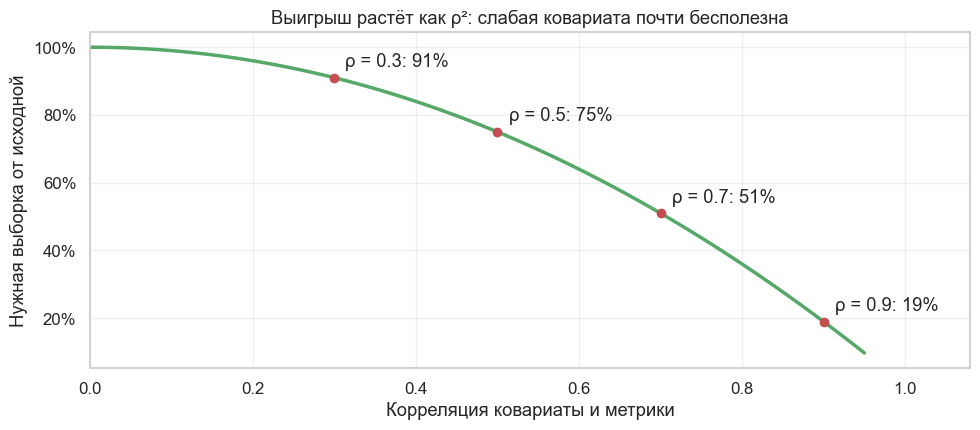

In [15]:
rhos = np.linspace(0, 0.95, 100)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rhos, 1 - rhos ** 2, color=GREEN, linewidth=2.5)
for rho in (0.3, 0.5, 0.7, 0.9):
    ax.scatter([rho], [1 - rho ** 2], color=RED, zorder=3)
    ax.annotate(f'ρ = {rho}: {1 - rho ** 2:.0%}', (rho, 1 - rho ** 2), textcoords='offset points', xytext=(8, 8))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_xlim(0, 1.08)
ax.set_xlabel('Корреляция ковариаты и метрики')
ax.set_ylabel('Нужная выборка от исходной')
ax.set_title('Выигрыш растёт как ρ²: слабая ковариата почти бесполезна')
plt.tight_layout()
plt.show()


**CUPED и регрессия.** Эффект CUPED с общим $\theta$ практически совпадает с коэффициентом при индикаторе группы в регрессии $Y = \alpha + \tau T + \theta X + \varepsilon$ (ANCOVA). Это помогает понимать и обобщать метод: несколько ковариат — это просто регрессия с несколькими признаками.


In [16]:
rng = np.random.default_rng(42)
y_c_one, x_c_one = generate_metric_covariate(rng, (1, 1_000), 0.7)
y_t_one, x_t_one = generate_metric_covariate(rng, (1, 1_000), 0.7)
y_t_one = y_t_one + 20

cuped_c_one, cuped_t_one = apply_cuped(y_c_one, x_c_one, y_t_one, x_t_one)
design = np.column_stack([
    np.ones(2_000),
    np.r_[np.zeros(1_000), np.ones(1_000)],
    np.r_[x_c_one[0], x_t_one[0]],
])
ols = sm.OLS(np.r_[y_c_one[0], y_t_one[0]], design).fit()

print(f'Эффект по CUPED:               {cuped_t_one.mean() - cuped_c_one.mean():.3f}')
print(f'Коэффициент при T в регрессии: {ols.params[1]:.3f}')


Эффект по CUPED:               36.876
Коэффициент при T в регрессии: 36.912


#### Какую ковариату выбрать

Выбор ковариаты — самая сложная часть CUPED. От него зависит, насколько чувствительнее станет критерий. Два требования:

* **Скоррелированность** определяет выигрыш: чем сильнее связь с метрикой, тем больше снижается дисперсия.
* **Независимость от воздействия** определяет корректность. Если взять в качестве ковариаты саму метрику во время эксперимента, то CUPED-метрика у всех станет нулём, и критерий никогда не увидит отличий.

Чаще всего берут значение метрики до эксперимента. Корреляция возникает из-за устойчивости поведения пользователей, а эксперимент не может повлиять на прошлое. Главное преимущество такой ковариаты — простота: легко посчитать и сложно ошибиться.

Чтобы снизить дисперсию сильнее, можно поэкспериментировать с длиной периода. Если эксперимент идёт неделю, можно использовать выручку за неделю до него, а можно за 4 или 8 недель. Длинный период особенно полезен для редких событий, когда пользователи покупают реже раза в неделю.

Если в поведении есть сезонность, попробуйте значение метрики за аналогичный период прошлого сезона.

Можно использовать и данные, полученные во время эксперимента, если воздействие на них точно не влияет. Например, данные о погоде. А вот что будет, если ковариата всё же зависит от воздействия:


In [17]:
rng = np.random.default_rng(42)
size = (2_000, 1_000)
y_c, x_c = generate_metric_covariate(rng, size, 0.7)
y_t, x_t = generate_metric_covariate(rng, size, 0.7)
effect = 20.0
y_t_effect = y_t + effect

# Плохая ковариата: собрана во время теста, и воздействие на неё повлияло
x_t_shifted = x_t + effect
good_c, good_t = apply_cuped(y_c, x_c, y_t_effect, x_t)
bad_c, bad_t = apply_cuped(y_c, x_c, y_t_effect, x_t_shifted)
print(f'Истинный эффект:                          {effect:.1f}')
print(f'CUPED с ковариатой до теста:              {(good_t.mean(axis=1) - good_c.mean(axis=1)).mean():.1f}')
print(f'CUPED с ковариатой, задетой воздействием: {(bad_t.mean(axis=1) - bad_c.mean(axis=1)).mean():.1f}')


Истинный эффект:                          20.0
CUPED с ковариатой до теста:              19.6
CUPED с ковариатой, задетой воздействием: 5.6


Ковариата «съела» большую часть эффекта. Ошибки такого рода особенно опасны: тест выглядит чувствительнее, а эффект исчезает без всяких предупреждений.

#### На каких данных считать $\theta$

Есть несколько вариантов:

1. На объединённых данных контрольной и экспериментальной групп.
2. На данных контрольной группы.
3. На данных экспериментальной группы.
4. На исторических данных.

Выводы [обзора X5](https://habr.com/ru/companies/X5Tech/articles/780270/#:~:text=%D0%9D%D0%B0%20%D1%87%D1%91%D0%BC%20%D0%BE%D1%86%D0%B5%D0%BD%D0%B8%D0%B2%D0%B0%D1%82%D1%8C%20Theta), где приведены симуляции:

* Если группы велики, а эксперимент сильно не меняет связь ковариаты с метрикой, все способы дают почти одинаковый результат.
* Если группы достаточно велики, лучше оценивать $\theta$ на объединённых данных.
* Если группы малы, лучше может сработать оценка на актуальных исторических данных.

В любом случае выбранный способ стоит проверить на A/A-тестах. Грубая ошибка — посчитать **разные $\theta$ в группах и не центрировать ковариату**. Тогда в тесте и контроле вычитаются разные величины и в разницу средних попадает слагаемое $(\theta^{ctrl} - \theta^{test}) \bar{X}$. Проверим на маленьких группах:


In [18]:
rng = np.random.default_rng(42)
n_sim, n_small = 20_000, 50
size = (n_sim, n_small)
y_c, x_c = generate_metric_covariate(rng, size, 0.7)
y_t, x_t = generate_metric_covariate(rng, size, 0.7)
y_hist, x_hist = generate_metric_covariate(rng, (n_sim, 1_000), 0.7)
pooled_x_mean = np.hstack([x_c, x_t]).mean(axis=1, keepdims=True)

theta_pooled = calculate_theta(np.hstack([y_c, y_t]), np.hstack([x_c, x_t]))
theta_c, theta_t = calculate_theta(y_c, x_c), calculate_theta(y_t, x_t)
theta_hist = calculate_theta(y_hist, x_hist)

schemes = {
    'Общий θ на тесте и контроле': (theta_pooled, theta_pooled),
    'θ только по контролю': (theta_c, theta_c),
    'θ только по тесту': (theta_t, theta_t),
    'θ по истории': (theta_hist, theta_hist),
    'Свой θ в группе, X без центрирования': (theta_c, theta_t),
}
rows = {'Без CUPED': np.mean(stats.ttest_ind(y_t, y_c, axis=1).pvalue < ALPHA)}
for name, (t_c, t_t) in schemes.items():
    rows[name] = np.mean(stats.ttest_ind(y_t - t_t * x_t, y_c - t_c * x_c, axis=1).pvalue < ALPHA)
adjusted_c, adjusted_t = y_c - theta_c * (x_c - pooled_x_mean), y_t - theta_t * (x_t - pooled_x_mean)
rows['Свой θ в группе, X центрирована'] = np.mean(stats.ttest_ind(adjusted_t, adjusted_c, axis=1).pvalue < ALPHA)
print(f'A/A, n = {n_small} на группу')
print(pd.Series(rows, name='Ошибка I рода').round(3).to_string())


A/A, n = 50 на группу
Без CUPED                               0.050
Общий θ на тесте и контроле             0.051
θ только по контролю                    0.053
θ только по тесту                       0.053
θ по истории                            0.051
Свой θ в группе, X без центрирования    0.776
Свой θ в группе, X центрирована         0.054


Тест с разными $\theta$ без центрирования полностью сломан, тогда как все варианты с общим $\theta$ на 50 пользователях держат 5%. На ещё меньших группах в обзоре X5 оценка по одной группе тоже давала неравномерные p-value в A/A-тестах, поэтому при совсем малых выборках $\theta$ лучше брать из истории. Свой $\theta$ в группах допустим, только если ковариата центрирована: это регрессия со взаимодействием группы и ковариаты, тот же приём использует MLRATE.


### [Predictive CUPED](https://www.youtube.com/watch?v=2ZhSNahXCl8)


**Предиктивный CUPED** похож на обычный: он тоже очищает метрику от шума с помощью ковариат. Разница в том, что коэффициенты подбираются на контрольной группе, куда воздействие не попало, а ковариат может быть несколько.

**Алгоритм**

1. Вычислить метрику $Y$ и вектор ковариат $X$ для каждого пользователя обеих групп.
2. На контрольной группе обучить регрессию: $\hat{Y} = \alpha^c + \theta^c X$.
3. Применить её к обеим группам: $\hat{Y}^c = \alpha^c + \theta^c X^c$ и $\hat{Y}^t = \alpha^c + \theta^c X^t$.
4. Посчитать очищенные метрики: $Y^c_{resid} = Y^c - \hat{Y}^c$ и $Y^t_{resid} = Y^t - \hat{Y}^t$.
5. Применить статистический тест к очищенным метрикам.

С одной ковариатой это почти обычный CUPED: $\theta$ лишь оценён на меньшем объёме данных, поэтому мощность на малых выборках может быть чуть ниже. Выигрыш появляется, когда ковариат несколько.

**Важно:** контрольные пользователи участвуют в обучении, а тестовые — нет, поэтому модель объясняет контроль лучше, чем тест. Для линейной модели с небольшим числом ковариат это почти незаметно, а для гибких моделей приводит к заниженной стандартной ошибке (см. сравнение ниже). Гибкую модель стоит обучать на предпериоде, то есть переходить к CUPAC, или использовать кросс-фитинг, как в MLRATE.


### [CUPAC](https://careersatdoordash.com/blog/improving-experimental-power-through-control-using-predictions-as-covariate-cupac/)


**CUPAC (Control Using Predictions As Covariate)** ещё одно расширение CUPED от DoorDash. Вместо готовой ковариаты он использует предсказание целевой метрики моделью машинного обучения $g(X)$, и $\theta$ считается для него по обычной формуле. Цель — предсказание с максимальной корреляцией с метрикой, а корреляция и определяет снижение дисперсии.

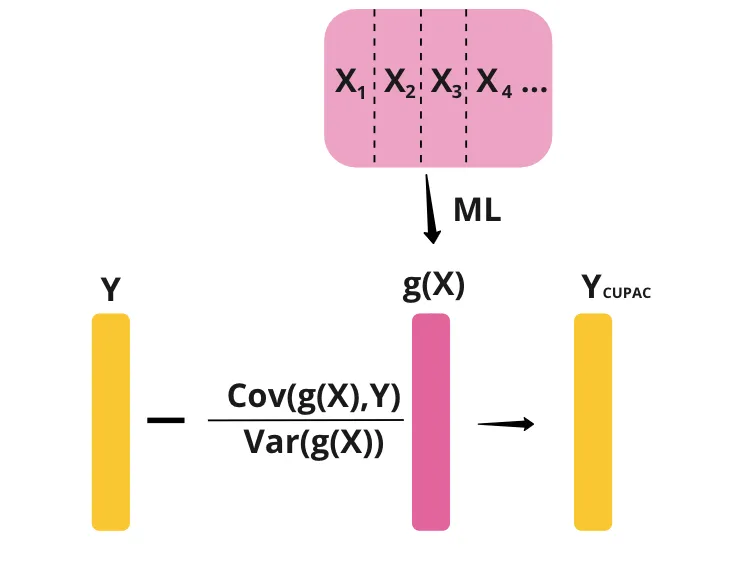

Требования те же, что и к ковариате в CUPED, но нарушить их проще:

* модель обучается на данных **до** эксперимента, а предсказания строятся для пользователей эксперимента;
* признаки собраны до старта эксперимента, поэтому воздействие на них повлиять не могло;
* группа не входит в признаки.


### [MLRATE](https://arxiv.org/pdf/2106.07263)


**MLRATE (Machine Learning Regression-Adjusted Treatment Effect Estimator)** предложен Го и соавторами в 2021 году.

Как и CUPAC, MLRATE обучает модель прогнозировать $Y$ по $X$. Назовём прогноз $g(X)$. Вместо вычитания $g(X)$ из $Y$ MLRATE включает его вместе с индикатором группы $T$ в регрессию и берёт эффект из её коэффициента.

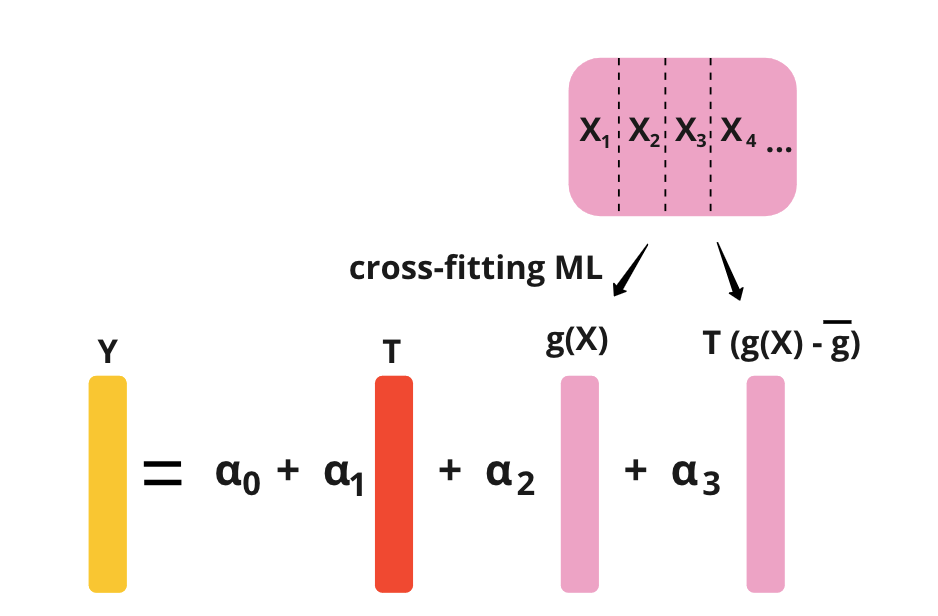


**Алгоритм**

1. Разобьём данные $(Y_i, X_i, T_i)_{i=1}^N$ случайно на $K$ равных частей. $I_k$ — индексы $k$-й части, $I_k^c = \{1, 2, \ldots, N\} \setminus I_k$ — все остальные.
2. Для каждой части $k$ обучим ML-алгоритм на данных $(Y_i, X_i)_{i \in I_k^c}$ и получим функцию $\hat{g}_k$. Прогнозы для $I_k$ делает только модель, не видевшая эти данные (**кросс-фитинг**).
3. Посчитаем среднее прогнозов $\bar{g} = \frac{1}{N} \sum_i \hat{g}_{k(i)}(X_i)$, где $k(i)$ — номер части, содержащей наблюдение $i$.
4. Найдём оценку $\hat{\alpha}_1$ методом наименьших квадратов в регрессии

$$
Y_i = \alpha_0 + \alpha_1 T_i + \alpha_2 \hat{g}_{k(i)}(X_i) + \alpha_3 T_i \left( \hat{g}_{k(i)}(X_i) - \bar{g} \right) + \epsilon_i
$$

Здесь $\hat{\alpha}_1$ — оценка эффекта. Стандартную ошибку берём робастную (HC). Авторы показали, что асимптотически метод не хуже разницы средних, даже если прогноз бесполезен. В A/A-тестах по 48 метрикам Facebook дисперсия оказалась более чем на 70% ниже, чем у разницы средних, и примерно на 19% ниже, чем при корректировке по одной ковариате.


### Сравнение методов с ML

Метрика нелинейно зависит от пяти признаков, поэтому линейная корректировка улавливает только часть сигнала. Модель для всех методов одинаковая: случайный лес. Отдельно посмотрим на две ошибки: обучение на контроле с последующим предсказанием для него же и обучение на данных самого эксперимента.


Истинный эффект: 0.4
                                   Ошибка I рода  Мощность  Оценка эффекта  SD оценки  Средняя SE
Без корректировки                          0.047     0.773           0.387      0.139       0.143
CUPED                                      0.013     0.893           0.392      0.111       0.123
Predictive CUPED, линейная модель          0.020     0.987           0.392      0.092       0.102
Predictive CUPED, лес на контроле          0.107     1.000           0.423      0.075       0.066
CUPAC, модель на истории                   0.040     1.000           0.397      0.068       0.075
CUPAC, лес на данных теста                 0.027     1.000           0.199      0.039       0.042
MLRATE                                     0.053     1.000           0.403      0.078       0.081


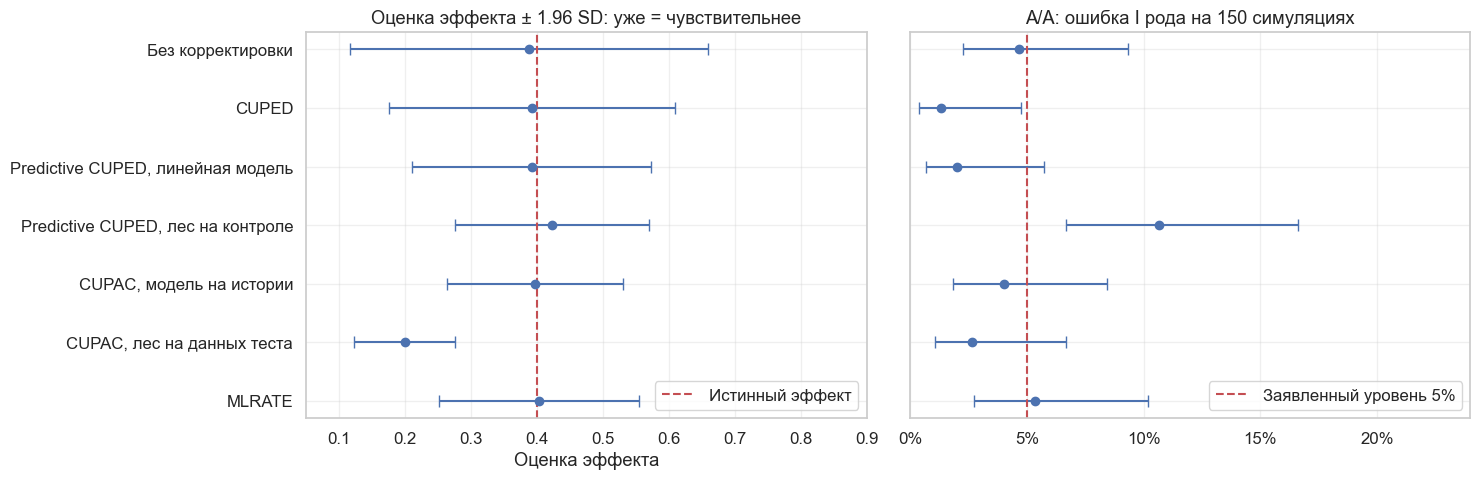

In [19]:
ML_CONFIG = {
    "n_simulations": 150,
    "n_users": 1_000,  # на группу
    "n_history": 5_000,
    "effect": 0.4,
}


def generate_features(rng: np.random.Generator, n: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Генерирует признаки до эксперимента, предыдущее значение метрики и саму метрику."""
    features = rng.normal(size=(n, 5))
    signal = 3 * np.sin(features[:, 0]) + 2 * (features[:, 1] > 0) * features[:, 2] + features[:, 3] ** 2
    metric = 10 + signal + rng.normal(0, 1.5, n)
    pre_metric = 10 + 0.5 * signal + rng.normal(0, 2.0, n)
    return np.column_stack([features, pre_metric]), pre_metric, metric


def make_forest() -> RandomForestRegressor:
    """Создаёт одну и ту же ML-модель для всех методов."""
    return RandomForestRegressor(n_estimators=20, min_samples_leaf=3, n_jobs=-1, random_state=0)


def adjust(y: np.ndarray, covariate: np.ndarray) -> np.ndarray:
    """Вычитает из метрики ковариату с оптимальным θ."""
    return y - np.cov(covariate, y)[0, 1] / covariate.var(ddof=1) * covariate


def mlrate(y: np.ndarray, features: np.ndarray, is_pilot: np.ndarray, rng: np.random.Generator) -> tuple[float, float]:
    """Считает MLRATE на двух фолдах кросс-фитинга: эффект и робастную SE."""
    folds = np.array_split(rng.permutation(y.size), 2)
    prediction = np.empty(y.size)
    for fit_part, predict_part in ((folds[0], folds[1]), (folds[1], folds[0])):
        prediction[predict_part] = make_forest().fit(features[fit_part], y[fit_part]).predict(features[predict_part])
    design = np.column_stack([np.ones(y.size), is_pilot, prediction, is_pilot * (prediction - prediction.mean())])
    fit = sm.OLS(y, design).fit(cov_type='HC1')
    return float(fit.params[1]), float(fit.bse[1])


def run_ml_methods(y: np.ndarray, features: np.ndarray, pre_metric: np.ndarray, is_pilot: np.ndarray,
                   history_model: RandomForestRegressor, rng: np.random.Generator) -> dict[str, tuple[float, float]]:
    """Применяет все способы корректировки к одному эксперименту."""
    in_control = ~is_pilot

    def compare(metric):
        pilot, control = metric[is_pilot], metric[in_control]
        return pilot.mean() - control.mean(), np.sqrt(pilot.var(ddof=1) / pilot.size + control.var(ddof=1) / control.size)

    return {
        'Без корректировки': compare(y),
        'CUPED': compare(adjust(y, pre_metric)),
        'Predictive CUPED, линейная модель': compare(y - LinearRegression().fit(features[in_control], y[in_control]).predict(features)),
        'Predictive CUPED, лес на контроле': compare(y - make_forest().fit(features[in_control], y[in_control]).predict(features)),
        'CUPAC, модель на истории': compare(adjust(y, history_model.predict(features))),
        'CUPAC, лес на данных теста': compare(adjust(y, make_forest().fit(features, y).predict(features))),
        'MLRATE': mlrate(y, features, is_pilot, rng),
    }


def simulate_ml(n_simulations: int, n_users: int, n_history: int, effect: float) -> dict[str, dict[str, np.ndarray]]:
    """Сравнивает методы с ML на A/A и A/B."""
    rng = np.random.default_rng(42)
    features_hist, _, metric_hist = generate_features(rng, n_history)
    history_model = make_forest().fit(features_hist, metric_hist)
    is_pilot = np.arange(2 * n_users) >= n_users
    result: dict[str, dict[str, list]] = {}
    for _ in tqdm(range(n_simulations), desc='Симуляции с ML'):
        features, pre_metric, metric = generate_features(rng, 2 * n_users)
        for key, shift in (('aa', 0.0), ('ab', effect)):
            estimates = run_ml_methods(metric + shift * is_pilot, features, pre_metric, is_pilot, history_model, rng)
            for name, (delta, se) in estimates.items():
                row = result.setdefault(name, {'aa': [], 'ab': [], 'delta': [], 'se': []})
                row[key].append(z_pvalue(delta, se) < ALPHA)
                if key == 'ab':
                    row['delta'].append(delta)
                    row['se'].append(se)
    return {name: {key: np.array(values) for key, values in row.items()} for name, row in result.items()}


ml_results = simulate_ml(**ML_CONFIG)
ml_table = pd.DataFrame({
    name: {
        'Ошибка I рода': row['aa'].mean(),
        'Мощность': row['ab'].mean(),
        'Оценка эффекта': row['delta'].mean(),
        'SD оценки': row['delta'].std(ddof=1),
        'Средняя SE': row['se'].mean(),
    } for name, row in ml_results.items()
}).T
print(f"Истинный эффект: {ML_CONFIG['effect']}")
print(ml_table.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
names = list(ml_results)[::-1]
axes[0].errorbar(ml_table.loc[names, 'Оценка эффекта'], names, xerr=1.96 * ml_table.loc[names, 'SD оценки'],
                 fmt='o', color=BLUE, capsize=4)
axes[0].axvline(ML_CONFIG['effect'], color=RED, linestyle='--', label='Истинный эффект')
axes[0].set_title('Оценка эффекта ± 1.96 SD: уже = чувствительнее')
axes[0].set_xlabel('Оценка эффекта')
axes[0].set_xlim(0.05, 0.9)
axes[0].legend(loc='lower right')
plot_rates(axes[1], {name: row['aa'] for name, row in ml_results.items()}, f"A/A: ошибка I рода на {ML_CONFIG['n_simulations']} симуляциях")
axes[1].set_xlim(0, 0.24)
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()


Что видно по результатам:

* **CUPED** помогает, но слабо: его ковариата содержит только часть сигнала.
* **Линейная модель на нескольких ковариатах** заметно лучше: добавились признаки.
* **CUPAC и MLRATE** дают самые узкие корректные оценки: оценка эффекта не смещена, а стандартное отклонение вдвое меньше, чем без корректировки.
* **Гибкая модель на контроле** выглядит мощной, но средняя SE (0.066) меньше реального разброса (0.075), поэтому ошибка I рода завышена (10.7%).
* **Модель, обученная на данных теста**, запомнила значения метрики вместе с эффектом и вычла его: оценка равна 0.20 при истинном эффекте 0.4. В [статье Авито](https://habr.com/ru/companies/avito/articles/590105/) обучение и предсказание на одних данных с CatBoost, наоборот, раздуло ошибку I рода до 0.14 при заявленных 0.05. Симптомы разные, причина одна: **обучать модель и применять её на одних и тех же данных нельзя**.

Симуляций здесь всего 150, потому что обучать модели дорого, так что доверительный интервал для ошибки I рода широкий: он составляет примерно ±3.5 процентного пункта. Надёжнее смотреть на соотношение SD и средней SE.


## Какой метод выбрать

| Ситуация | Что использовать | Чего избегать |
|---|---|---|
| Есть история метрики у большинства пользователей | CUPED | Ковариаты, собранной после старта теста |
| Есть много признаков до теста и нелинейные зависимости | CUPAC, MLRATE | Обучения модели на данных эксперимента |
| Метрика отношения | Линеаризация, затем CUPED | Теста на уровне показов или заказов |
| Метрика с тяжёлым хвостом | Винзоризация порогом с предпериода | Своего порога в каждой группе и удаления по метрике во время теста |
| Сильно различающиеся сегменты, нет истории | Постстратификация | Страт, на которые влияет воздействие |
| Пользователи сильно различаются по шумности | VWE | Выводов о размере эффекта без проверки |
| Вычисления слишком дорогие | Бакетизация | Ожиданий, что вырастет мощность |

Методы часто сочетаются: например, винзоризация, затем линеаризация, затем CUPED. Любую комбинацию перед внедрением стоит проверить на A/A-тестах на своих данных.


## Культура A/B-тестирования: когда процесс важнее математики?


В мире, где каждая компания мечтает стать data-driven, A/B-тестирование превратилось в нечто большее, чем инструмент принятия решений. Это образ мышления и культура. Парадокс в том, что многие организации, зациклившись на статистических тонкостях (поправках Бонферрони, CUPED, стратификации), упускают главное: скорость и качество тестирования определяются не только формулами, но и тем, как устроен процесс.

Можно годами оптимизировать дисперсию и внедрять передовые методы анализа, но если гипотезы неделями лежат в почте у менеджеров, если платформа требует ручного вмешательства на каждом шаге, если команда не понимает, какие эксперименты уже запущены и как они взаимодействуют, математика не спасёт.

**Почему культура тестирования важнее, чем кажется**

Представьте: Data Scientist тратит три дня на расчёт необходимой выборки, применяет все возможные методы снижения дисперсии, запускает тест, и тут выясняется, что маркетинг уже проводит кампанию на ту же аудиторию. Или что метрику, которую все считали основной, никто не согласовал. Или что результаты теста нельзя раскатить, потому что изменения не были заранее интегрированы в CI/CD.

Такие ситуации — не редкость. Они происходят не из-за недостатка знаний статистики, а из-за отсутствия чётких процессов, стандартов и инфраструктуры.


### 1. Шаблоны и стандарты: как избавиться от хаоса

Одна из самых больших потерь времени в A/B-тестировании — не сам эксперимент, а его подготовка. Бесконечные уточнения: «Что именно мы тестируем?», «Какие метрики будем смотреть?», «Какой минимальный эффект нас устроит?»

Хорошая культура тестирования начинается с единого языка. Вместо долгих обсуждений в почте или чатах — чёткие шаблоны. Например:

```
Гипотеза: мы ожидаем, что увеличение кнопки «Купить» на 20% приведёт к относительному росту конверсии
в покупку на 1.5% для всех пользователей мобильного приложения, потому что текущий размер кнопки
ниже минимального рекомендуемого для удобного нажатия.

Метрики:
* Основная: конверсия в покупку (ожидаемый эффект: +1.5%, MDE: +0.8%)
* Барьерная (guardrail): средний чек (допустимое изменение: ±3%)

Длительность: 14 дней
```

Когда такие шаблоны становятся стандартом, лишней бюрократии становится гораздо меньше.


### 2. Автоматизация расчётов: когда отчёты генерируются сами

Второй бич скорости тестирования — ручная подготовка отчётов. Data Scientist тратит часы на выгрузку данных, проверку аномалий и пересчёт метрик, а потом оказывается, что кто-то забыл учесть новый фильтр, и всё нужно переделывать.

Решение — автоматизированные дашборды и расчёты, которые:

* Считают метрики автоматически и регулярно. Если результаты видны каждый день, нужна защита от подглядывания: либо решение принимается только в конце теста, либо используется [последовательное тестирование](<../../../2. Квази-эксперименты/Теоретический блок/01. Последовательное тестирование>).
* Автоматически применяют методы снижения дисперсии и поправки на множественное тестирование.
* Показывают не только статистическую, но и практическую значимость (например: «Эффект +1.2%, но доверительный интервал включает +0.3%, возможно, изменение не стоит внедрять»).
* Отправляют уведомления, когда тест набрал расчётную выборку.


### 3. A/B-платформа: конвейер для экспериментов

Без нормальной платформы A/B-тестирование превращается в рутину. Хорошая платформа должна:

* Автоматически распределять пользователей по группам с учётом слоёв, чтобы тесты не мешали друг другу.
* Интегрироваться с системой развёртывания, чтобы изменения можно было включать и выключать мгновенно.
* Хранить историю всех экспериментов, чтобы не повторять одни и те же тесты.
* Позволять настраивать сценарии тестов без участия разработчиков (например: «Проверить три варианта заголовка на главной странице»).

Когда платформа работает как часы, команда тратит время не на настройку экспериментов, а на их анализ.


### 4. Календарь тестов: как не утонуть в трафике

Одна из самых распространённых проблем — конфликты тестов. Маркетинг запускает промокампанию, продуктовая команда тестирует новый дизайн, а аналитики проверяют алгоритм рекомендаций, и всё это на одной аудитории. В итоге результаты сложно интерпретировать.

Календарь тестов решает эту проблему. В нём указывается:

* Какие эксперименты запущены.
* На какую аудиторию они влияют.
* Когда ожидаются результаты.
* Какие метрики они затрагивают.

Это позволяет планировать тесты так, чтобы они не мешали друг другу.


### 5. Слои (Layering)

Когда тестов много, а трафика мало, без слоёв не обойтись. Идея проста: в каждом слое пользователи распределяются по группам независимо от других слоёв (хешированием с отдельной солью). Например:

* Слой 1: изменения в ценообразовании.
* Слой 2: новый дизайн карточек товаров.
* Слой 3: разные алгоритмы рекомендаций.

Так можно запускать десятки тестов одновременно. Важно, что слои обеспечивают независимость **распределения по группам**, но не отсутствие взаимодействия самих изменений. Если новая цена и новая карточка усиливают друг друга, слои этого не устранят. Поэтому тесты, которые могут влиять друг на друга, кладут в один слой, где они не пересекаются.


## Заключение

Снизить дисперсию можно разными способами, и общая логика у них одна: убрать из метрики шум, не зависящий от воздействия, и не задеть сам эффект. Почти все ошибки в этих методах связаны с нарушением второй части — когда очистка, ковариата или модель используют данные, на которые воздействие уже повлияло.

Но математика работает, только когда отлажен процесс. Культура тестирования — это не про инструменты, а про людей. Можно купить самую продвинутую A/B-платформу и нанять лучших Data Scientist, но если тестирование остаётся разовой акцией, а не частью ежедневной работы, усилия будут напрасны.

Культура тестирования — это когда:

* Продуктовые менеджеры формулируют гипотезы до начала разработки, а не после.
* Маркетинг согласовывает кампании с календарём тестов.
* Разработчики сразу закладывают возможность A/B-тестирования в новые фичи.
* Руководство понимает, что не все тесты дают значимый результат, и это нормально.

Когда эти принципы работают, скорость тестирования вырастает в разы. И тогда уже можно заниматься тонкой настройкой статистических методов, потому что процесс больше не тормозит сам себя.
